# Session Recurrent Network Viewer

Load a network fitted directly to one recurrent neural dataset, then compare target activity with individual network units and inspect each session's dense recurrent weights.

Each session has one unit per unique neuron in its activity array. New networks infer their initial states from the first observed target time bins; legacy checkpoints retain same initial state inferred from the observed target prefix (zero for legacy checkpoints)s. Every simulation samples fresh input noise, including during evaluation.


In [1]:
%matplotlib inline

import importlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.decomposition import PCA
from utils import experiment_param

import _8_LatentNetwork as ln
importlib.reload(ln)

dirpath = '/Users/kimchm/Documents/KimNiNature2024/MatConverted2Python/' 
par = experiment_param.ExperimentParam(dirpath)

def return_checkpoint_path(n_input_components, recurrent_type, recurrent_rank):

    device = 'cpu'  # 'cuda', 'cuda:0', 'mps', or 'gpu' if available.
    dataset_id = '0'  # filename ID: activity0.npy
    n_input_types = 2
    n_input_components = n_input_components
    input_noise_std = 0.1
    recurrent_type = recurrent_type  # 'fullconn' or 'lowrank'
    recurrent_rank = recurrent_rank  # set a positive integer for lowrank
    checkpoint_path = Path(ln.latent_network_checkpoint_path(
        dataset_id=dataset_id,
        n_input_types=n_input_types,
        n_input_components=n_input_components,
        input_noise_std=input_noise_std,
        recurrent_type=recurrent_type,
        recurrent_rank=recurrent_rank,
    ))
    print('available datasets:', ln.available_training_datasets())
    print('checkpoint:', checkpoint_path)
    print('exists:', checkpoint_path.exists())
    print('device:', device)
    return checkpoint_path


## Load The Trained Model

`results` contains the session networks, the selected dataset, and loss history. Train this checkpoint first if it does not exist:

```python
results = ln.train_latent_network(
    dataset_id=dataset_id,
    n_input_types=n_input_types,
    n_input_components=n_input_components,
    input_noise_std=input_noise_std,
    checkpoint_path=str(checkpoint_path),
    device=device,
    recurrent_type=recurrent_type,
    recurrent_rank=recurrent_rank,
)
```


In [2]:
checkpoint_path_fullconn = return_checkpoint_path(n_input_components=1, recurrent_type='fullconn', recurrent_rank=None)
checkpoint_path_lowrank  = return_checkpoint_path(n_input_components=1, recurrent_type='lowrank', recurrent_rank=10)

results_fc = ln.load_latent_network(checkpoint_path=str(checkpoint_path_fullconn), device='cpu',)
results_lr  = ln.load_latent_network(checkpoint_path=str(checkpoint_path_lowrank), device='cpu',)

rnn_fc  = results_fc['rnn']
loss_fc = results_fc['loss_history']
rnn_lr  = results_lr['rnn']
loss_lr = results_lr['loss_history']

dataset = results_fc['dataset']
n_sessions = rnn_fc.n_sessions

available datasets: ['0']
checkpoint: data/training/recurrent/fullconn/latent_network_Dataset0_In1_fullconn.pt
exists: True
device: cpu
available datasets: ['0']
checkpoint: data/training/recurrent/lowrank/latent_network_Dataset0_In1_Rank10_lowrank.pt
exists: True
device: cpu


In [205]:
# Load one CD dot product per session for the selected dataset.
CDdotproduct = np.load(
    Path(ln.TRAINING_DATA_PATH) / f"CDdotproduct{dataset['id']}.npy",
    allow_pickle=False,
)
print('CDdotproduct shape:', CDdotproduct.shape)
# Access a session's value with CDdotproduct[fx].


CDdotproduct shape: (33,)


In [206]:
# Run the training-data generator first to save neuron_fraction{dataset_id}.npy.
neuron_fraction = np.load(
    Path(ln.TRAINING_DATA_PATH) / f"neuron_fraction{dataset['id']}.npy",
    allow_pickle=False,
)
print('neuron_fraction shape:', neuron_fraction.shape)
# Access a session's fraction with neuron_fraction[fx].


neuron_fraction shape: (33,)


## Choose An Example

The dataset is selected when training/loading the checkpoint. Change the session and condition below to inspect another example within it.


In [208]:
fx = rnn_fc.session_ids[0]
condition = rnn_fc.conditions[0]

print('conditions:', rnn_fc.conditions)
print('sessions:', rnn_fc.session_ids)
print('selected session units:', rnn_fc.n_units_by_session[fx])


conditions: ('P1', 'A1')
sessions: (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32)
selected session units: 395


## Plot Prediction Vs. Target

Rows correspond directly to the same neurons in both target activity and network unit activity. Columns are time bins.


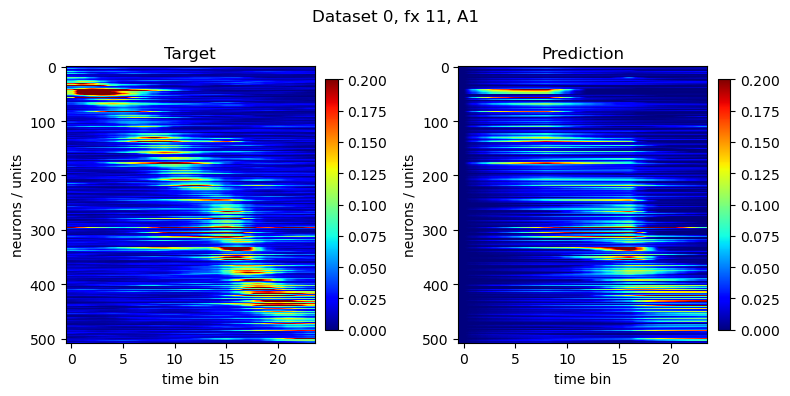

In [209]:
ln.plot_prediction_vs_target(
    results_lr,
    fx=11,
    condition='A1',
)
plt.show()


## Inspect The Recurrent Weight Matrix

`W[to_unit, from_unit]` is used in the update through `ReLU(h) @ W.T`. `rnn.recurrent_weight(fx)` returns the selected session's dense, fully trainable matrix. Its shape varies with the session's neuron count.


In [ ]:
wrec_path = Path(ln.SAVE_FIGURE_PATH) / 'wrec'
wrec_path.mkdir(parents=True, exist_ok=True)

for fx_plot in rnn_fc.session_ids:
    W = rnn_fc.recurrent_weight(fx_plot).detach().cpu().numpy()
    plt.figure(figsize=(6, 6))
    wlim = np.max(np.abs(W)) / 4 or 1.0
    plt.imshow(W, cmap='bwr', vmin=-wlim, vmax=wlim, aspect='auto')
    plt.title(f'Recurrent weight W: fx {fx_plot}')
    plt.xlabel('from unit')
    plt.ylabel('to unit')
    plt.colorbar(fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.savefig(wrec_path / f'dataset{dataset["id"]}_w{fx_plot}.png')
    plt.close()


# Wrec explained variance

In [3]:
# Dictionaries accommodate the different neuron counts in each session.
expvar_cumsum = {}
components = {}

for fx_idx in rnn_lr.session_ids:
    W = rnn_lr.recurrent_weight(fx_idx).detach().cpu().numpy()
    pca = PCA()
    pca.fit(W.T)
    expvar_cumsum[fx_idx] = np.cumsum(pca.explained_variance_ratio_)
    components[fx_idx] = pca.components_


In [4]:
effdim = np.array([
    int(np.argmax(values > 0.8) + 1)
    for fx_idx, values in expvar_cumsum.items()
])

print(effdim)
print(f'sessions with dim <= 4: {np.sum(effdim<=4)}/{len(effdim)}')

[6 7 7 1 4 8 3 8 5 3 2 4 7 5 1 2 4 6 3 1 1 2 3 2 5 7 2 7 4 2 1 2 2]
sessions with dim <= 4: 21/33


Text(0, 0.5, 'explained variance')

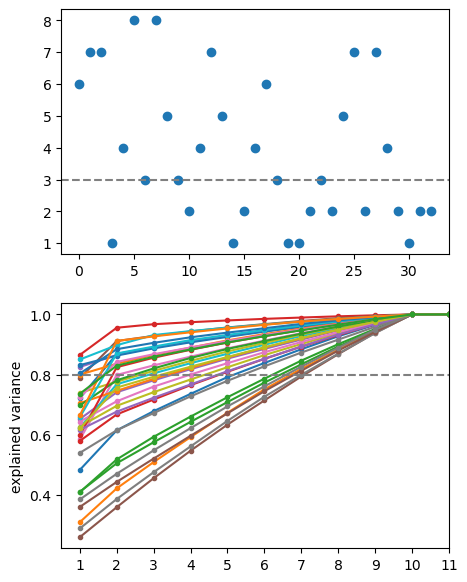

In [5]:
plt.figure(figsize=(5,7))
plt.subplot(211)
plt.plot(effdim,marker='o',linestyle='')
plt.axhline(3,color='gray',linestyle='--')
plt.subplot(212)
for fx_idx in rnn_lr.session_ids:
    plt.plot(np.arange(1,len(expvar_cumsum[fx_idx])+1), expvar_cumsum[fx_idx], marker='.')
plt.xlim([0.5, 11])
plt.xticks(np.arange(1,12))
plt.axhline(0.8, color='gray', linestyle='--')
plt.ylabel('explained variance')


## Sensory and response input vectors for `rank1_fx`


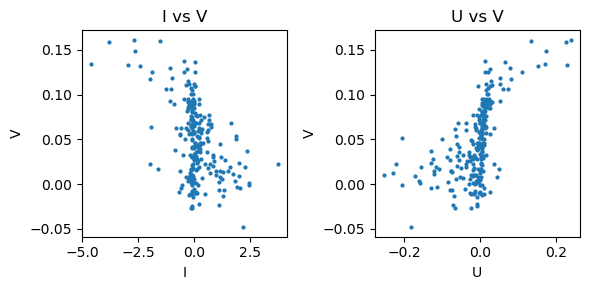

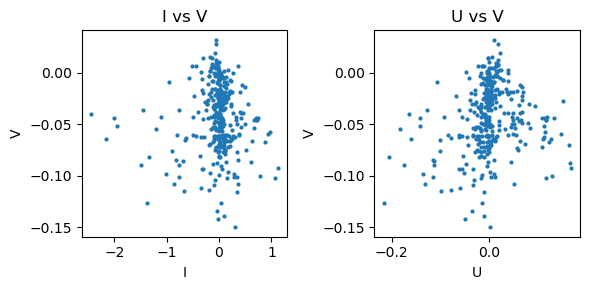

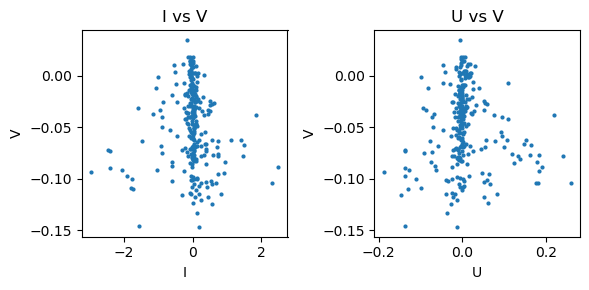

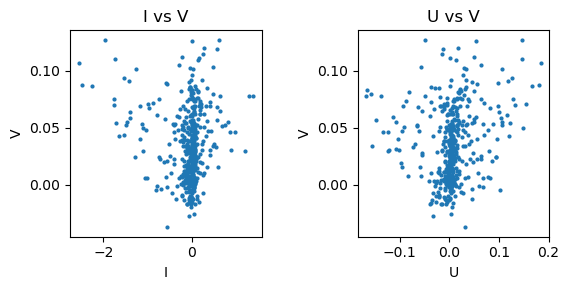

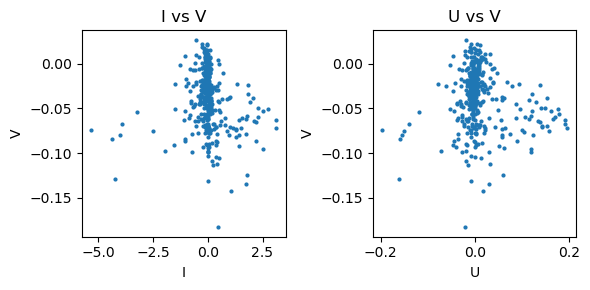

In [193]:
effdim_fx = 1
i = 5

for i in range(5):
        
    rank1_sessions = np.where(effdim == effdim_fx)[0]
    rank1_fx = rank1_sessions[i]

    # Use the same low-rank model that was used to select rank1_fx.
    rank1_session = rnn_lr.session_model(rank1_fx)
    W_rank1 = rank1_session.recurrent_weight().detach().cpu().numpy().copy()

    # Columns are singular vectors, ordered by decreasing singular value.
    # W_rank1 = U_rank1 @ np.diag(S_rank1) @ V_rank1.T
    U_rank1, S_rank1, Vh_rank1 = np.linalg.svd(W_rank1, full_matrices=False)
    V_rank1 = Vh_rank1.T
    # Leading left/right singular vectors: U_rank1[:, 0] and V_rank1[:, 0].

    # Input axes: (type, condition, component, neuron).
    # Default input type 0 is sensory; type 1 is response.
    # Copy to NumPy so inspecting/editing these arrays cannot change trained weights.
    rank1_session = rnn_lr.session_model(rank1_fx)
    input_vectors_rank1 = rank1_session.input_vectors.detach().cpu().numpy().copy()
    rank1_conditions = tuple(rank1_session.conditions)

    # Each condition maps to an array of shape (n_input_components, n_units).
    sensory_input_vectors = {
        condition_name: input_vectors_rank1[0, condition_index]
        for condition_index, condition_name in enumerate(rank1_conditions)
    }
    response_input_vectors = {
        condition_name: input_vectors_rank1[1, condition_index]
        for condition_index, condition_name in enumerate(rank1_conditions)
    }

    rank = 0

    plt.figure(figsize=(6,3))
    plt.subplot(121)
    plt.title('I vs V')
    plt.scatter(sensory_input_vectors['P1'], V_rank1[:,rank],s=4)
    plt.xlabel('I')
    plt.ylabel('V')
    plt.subplot(122)
    plt.title('U vs V')
    plt.scatter(U_rank1[:,rank], V_rank1[:,rank],s=4)
    plt.xlabel('U')
    plt.ylabel('V')
    plt.tight_layout()



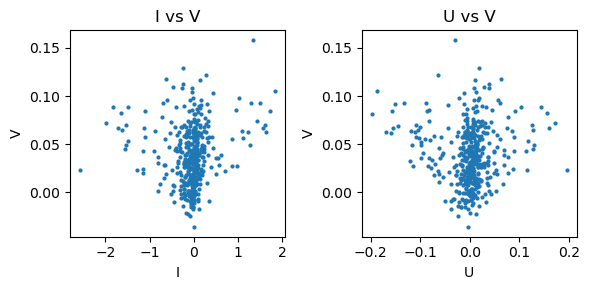

In [186]:
rank = 0

plt.figure(figsize=(6,3))
plt.subplot(121)
plt.title('I vs V')
plt.scatter(sensory_input_vectors['P1'], V_rank1[:,rank],s=4)
plt.xlabel('I')
plt.ylabel('V')
plt.subplot(122)
plt.title('U vs V')
plt.scatter(U_rank1[:,rank], V_rank1[:,rank],s=4)
plt.xlabel('U')
plt.ylabel('V')
plt.tight_layout()

Session 15: recurrent weight shape (204, 204)
Left singular vectors: (204, 204)
Right singular vectors: (204, 204)
Leading singular values: [6.347863   1.5607105  0.58235824 0.53971696 0.51338774]


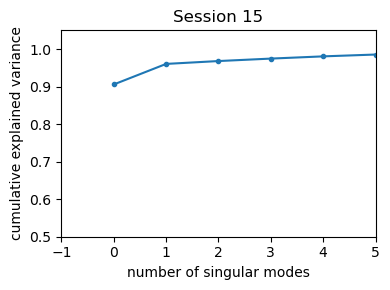

In [155]:

print(f'Session {rank1_fx}: recurrent weight shape {W_rank1.shape}')
print('Left singular vectors:', U_rank1.shape)
print('Right singular vectors:', V_rank1.shape)
print('Leading singular values:', S_rank1[:5])

cumulative_explained_variance = np.cumsum(S_rank1 ** 2) / np.sum(S_rank1 ** 2)
plt.figure(figsize=(4, 3))
plt.plot(cumulative_explained_variance, '.-')
plt.title(f'Session {rank1_fx}')
plt.xlabel('number of singular modes')
plt.ylabel('cumulative explained variance')
plt.ylim([0.5, 1.05])
plt.xlim([-1, 5])
plt.tight_layout()


In [ ]:
effdim_fx = 1
i = 5
cond = 'P1'
fx = 10

# rank1_sessions = np.where(effdim == effdim_fx)[0]
# rank1_fx = rank1_sessions[i]

# Use the same low-rank model that was used to select rank1_fx.
rank1_session = rnn_lr.session_model(fx)
W_rank1 = rank1_session.recurrent_weight().detach().cpu().numpy().copy()

# Columns are singular vectors, ordered by decreasing singular value.
# W_rank1 = U_rank1 @ np.diag(S_rank1) @ V_rank1.T
U_rank1, S_rank1, Vh_rank1 = np.linalg.svd(W_rank1, full_matrices=False)
V_rank1 = Vh_rank1.T
# Leading left/right singular vectors: U_rank1[:, 0] and V_rank1[:, 0].

# Input axes: (type, condition, component, neuron).
# Default input type 0 is sensory; type 1 is response.
# Copy to NumPy so inspecting/editing these arrays cannot change trained weights.
rank1_session = rnn_lr.session_model(fx)
input_vectors_rank1 = rank1_session.input_vectors.detach().cpu().numpy().copy()
rank1_conditions = tuple(rank1_session.conditions)

# Each condition maps to an array of shape (n_input_components, n_units).
sensory_input_vectors = {
    condition_name: input_vectors_rank1[0, condition_index]
    for condition_index, condition_name in enumerate(rank1_conditions)
}
response_input_vectors = {
    condition_name: input_vectors_rank1[1, condition_index]
    for condition_index, condition_name in enumerate(rank1_conditions)
}


## Bayesian Gaussian mixtures of neuron weight features

Each neuron is one row with four features: a left singular-vector entry, the matching right singular-vector entry, and its sensory and response input weights for `cond`. The defaults use the leading singular mode and input component 0. Every session in `rnn_lr` is fitted separately; the SVD and inputs are recomputed for that session.

Compare 1–3 components using five-fold cross-validation over neurons. Each fold learns its feature standardization from its training neurons only. Higher held-out mean log likelihood indicates better density fit; scores are converted back to the original feature units and should be compared within a session. Error bars show the standard deviation across folds. These scores evaluate the distribution of learned weights, not neural-activity prediction accuracy.

[BayesianGaussianMixture](https://scikit-learn.org/stable/modules/generated/sklearn.mixture.BayesianGaussianMixture.html) can assign negligible weight to some components. `n_components` is therefore a capacity limit; `n_active_components` counts weights above the configurable threshold. The concentration prior is fixed across candidate counts, and an identity covariance prior is used in standardized coordinates. Selection requires convergence in every fold and in the final refit; inspect the convergence columns if no candidate is selected.

Results remain in memory: `bgmm_summary` compares candidates, and `bgmm_results[fx]` stores neuron features, a scaler, all fitted models, and the selected model's labels/probabilities in the original neuron-row order. For example, `bgmm_results[fx]['fits'][2]['model']` retrieves the two-component fit. Models expect features transformed by that session's saved scaler.


In [195]:
from sklearn.mixture import BayesianGaussianMixture
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
import pandas as pd

bgmm_rnn = rnn_lr
bgmm_condition = 'P1'  # Uses the condition selected in the preceding cell.
bgmm_singular_mode = 0  # Column of U and V: 0 is the leading singular mode.
bgmm_input_component = 0  # Select one component to keep exactly four features.
bgmm_component_counts = (1, 2, 3)
bgmm_cv_folds = 5
bgmm_random_state = 0
bgmm_active_weight_threshold = 0.01
bgmm_model_options = dict(
    covariance_type='full',
    weight_concentration_prior_type='dirichlet_process',
    weight_concentration_prior=1.0,
    covariance_prior=np.eye(4),
    reg_covar=1e-6,
    n_init=3,
    max_iter=1000,
    tol=1e-3,
    random_state=bgmm_random_state,
)


In [196]:
bgmm_results = {}
bgmm_score_rows = []

for bgmm_fx in bgmm_rnn.session_ids:
    session = bgmm_rnn.session_model(bgmm_fx)
    condition_index = session.conditions.index(bgmm_condition)
    W_session = session.recurrent_weight().detach().cpu().numpy()
    U_session, _, Vh_session = np.linalg.svd(W_session, full_matrices=False)
    session_inputs = session.input_vectors.detach().cpu().numpy()
    # Row i refers to neuron i in ALL four columns (no sorting or flattening).
    X = np.column_stack((
        U_session[:, bgmm_singular_mode],
        Vh_session[bgmm_singular_mode, :],
        session_inputs[0, condition_index, bgmm_input_component, :],
        session_inputs[1, condition_index, bgmm_input_component, :],
    )).astype(float)
    n_neurons = X.shape[0]
    if not np.isfinite(X).all():
        raise ValueError(f'Session {bgmm_fx} has nonfinite weight features.')

    result = {
        'condition': bgmm_condition,
        'singular_mode': bgmm_singular_mode,
        'input_component': bgmm_input_component,
        'feature_names': ('U', 'V', 'sensory', 'response'),
        'features': X,
        'neuron_indices': np.arange(n_neurons),
        'fits': {},
        'best_n_components': None,
        'labels': None,
        'probabilities': None,
    }
    bgmm_results[bgmm_fx] = result
    # The final scaler is only for refitting on all neurons, not CV scoring.
    result['scaler'] = StandardScaler().fit(X)
    X_scaled = result['scaler'].transform(X)
    log_scale = np.log(result['scaler'].scale_).sum()

    # Reuse identical folds and training-only scalers for every component count.
    fold_data = []
    if n_neurons >= 3:
        splits = KFold(
            n_splits=min(bgmm_cv_folds, n_neurons), shuffle=True,
            random_state=bgmm_random_state,
        ).split(X)
        for train_index, test_index in splits:
            fold_scaler = StandardScaler().fit(X[train_index])
            fold_data.append((
                fold_scaler.transform(X[train_index]),
                fold_scaler.transform(X[test_index]),
                np.log(fold_scaler.scale_).sum(),
            ))

    for n_components in bgmm_component_counts:
        row = {
            'session': bgmm_fx, 'condition': bgmm_condition,
            'n_neurons': n_neurons, 'n_components': n_components,
            'cv_mean_log_likelihood': np.nan, 'cv_std_log_likelihood': np.nan,
            'train_mean_log_likelihood': np.nan,
            'n_active_components': np.nan,
            'cv_converged': False, 'converged': False, 'selected': False,
            'status': 'too few neurons to fit',
        }
        bgmm_score_rows.append(row)
        if n_neurons < max(2, n_components):
            continue

        fold_scores, fold_sizes, fold_converged = [], [], []
        if fold_data and all(len(train) >= max(2, n_components) for train, _, _ in fold_data):
            for train, test, fold_log_scale in fold_data:
                fold_model = BayesianGaussianMixture(
                    n_components=n_components, **bgmm_model_options,
                ).fit(train)
                # Change-of-variables correction gives density in original units.
                fold_scores.append(fold_model.score(test) - fold_log_scale)
                fold_sizes.append(len(test))
                fold_converged.append(bool(fold_model.converged_))
            row['cv_mean_log_likelihood'] = np.average(fold_scores, weights=fold_sizes)
            row['cv_std_log_likelihood'] = np.std(fold_scores, ddof=1)
            row['cv_converged'] = all(fold_converged)

        # Refit each candidate on every neuron for subsequent cluster analysis.
        model = BayesianGaussianMixture(
            n_components=n_components, **bgmm_model_options,
        ).fit(X_scaled)
        row['train_mean_log_likelihood'] = model.score(X_scaled) - log_scale
        row['n_active_components'] = int(np.sum(model.weights_ > bgmm_active_weight_threshold))
        row['converged'] = bool(model.converged_)
        if not fold_scores:
            row['status'] = 'too few neurons for cross-validation'
        elif not (row['cv_converged'] and row['converged']):
            row['status'] = 'not converged; increase max_iter or n_init'
        elif not np.isfinite(row['cv_mean_log_likelihood']):
            row['status'] = 'nonfinite cross-validation score'
        else:
            row['status'] = 'ok'
        result['fits'][n_components] = {
            'model': model,
            'weights': model.weights_.copy(),
            'labels': model.predict(X_scaled),
            'probabilities': model.predict_proba(X_scaled),
            'fold_log_likelihoods': np.asarray(fold_scores),
            'fold_converged': np.asarray(fold_converged, dtype=bool),
            'metrics': row,
        }

    eligible = [k for k, fit in result['fits'].items() if fit['metrics']['status'] == 'ok']
    if eligible:
        best_k = max(eligible, key=lambda k: result['fits'][k]['metrics']['cv_mean_log_likelihood'])
        best_fit = result['fits'][best_k]
        result['best_n_components'] = best_k
        result['labels'] = best_fit['labels']
        result['probabilities'] = best_fit['probabilities']
        best_fit['metrics']['selected'] = True
        print(f'Session {bgmm_fx}: best component limit = {best_k}; '
              f'active components = {best_fit["metrics"]["n_active_components"]}')
    else:
        print(f'Session {bgmm_fx}: no eligible CV fit; inspect bgmm_summary status.')

bgmm_summary = pd.DataFrame(bgmm_score_rows)
bgmm_summary


Session 0: best component limit = 3; active components = 3
Session 1: best component limit = 3; active components = 3
Session 2: best component limit = 3; active components = 3
Session 3: best component limit = 3; active components = 3
Session 4: best component limit = 3; active components = 3
Session 5: best component limit = 3; active components = 3
Session 6: best component limit = 3; active components = 3
Session 7: best component limit = 3; active components = 3
Session 8: best component limit = 3; active components = 3
Session 9: best component limit = 3; active components = 3
Session 10: best component limit = 3; active components = 3
Session 11: best component limit = 3; active components = 3
Session 12: best component limit = 3; active components = 3
Session 13: best component limit = 3; active components = 3
Session 14: best component limit = 3; active components = 3
Session 15: best component limit = 3; active components = 3
Session 16: best component limit = 3; active compo

,session,condition,n_neurons,n_components,cv_mean_log_likelihood,cv_std_log_likelihood,train_mean_log_likelihood,n_active_components,cv_converged,converged,selected,status
0,0,P1,395,1,4.431198,0.353752,4.533214,1,True,True,False,ok
1,0,P1,395,2,5.328527,0.223547,5.465401,2,True,True,False,ok
2,0,P1,395,3,5.335737,0.273013,5.536743,3,True,True,True,ok
3,1,P1,1173,1,5.076014,0.129583,5.118716,1,True,True,False,ok
4,1,P1,1173,2,5.796377,0.060806,5.838058,2,True,True,False,ok
...,...,...,...,...,...,...,...,...,...,...,...,...
94,31,P1,259,2,4.200739,0.454554,4.359592,2,True,True,False,ok
95,31,P1,259,3,4.281411,0.436277,4.536566,3,True,True,True,ok
96,32,P1,485,1,3.669431,0.455573,3.826756,1,True,True,False,ok
97,32,P1,485,2,5.355749,0.304369,5.474173,2,True,True,False,ok


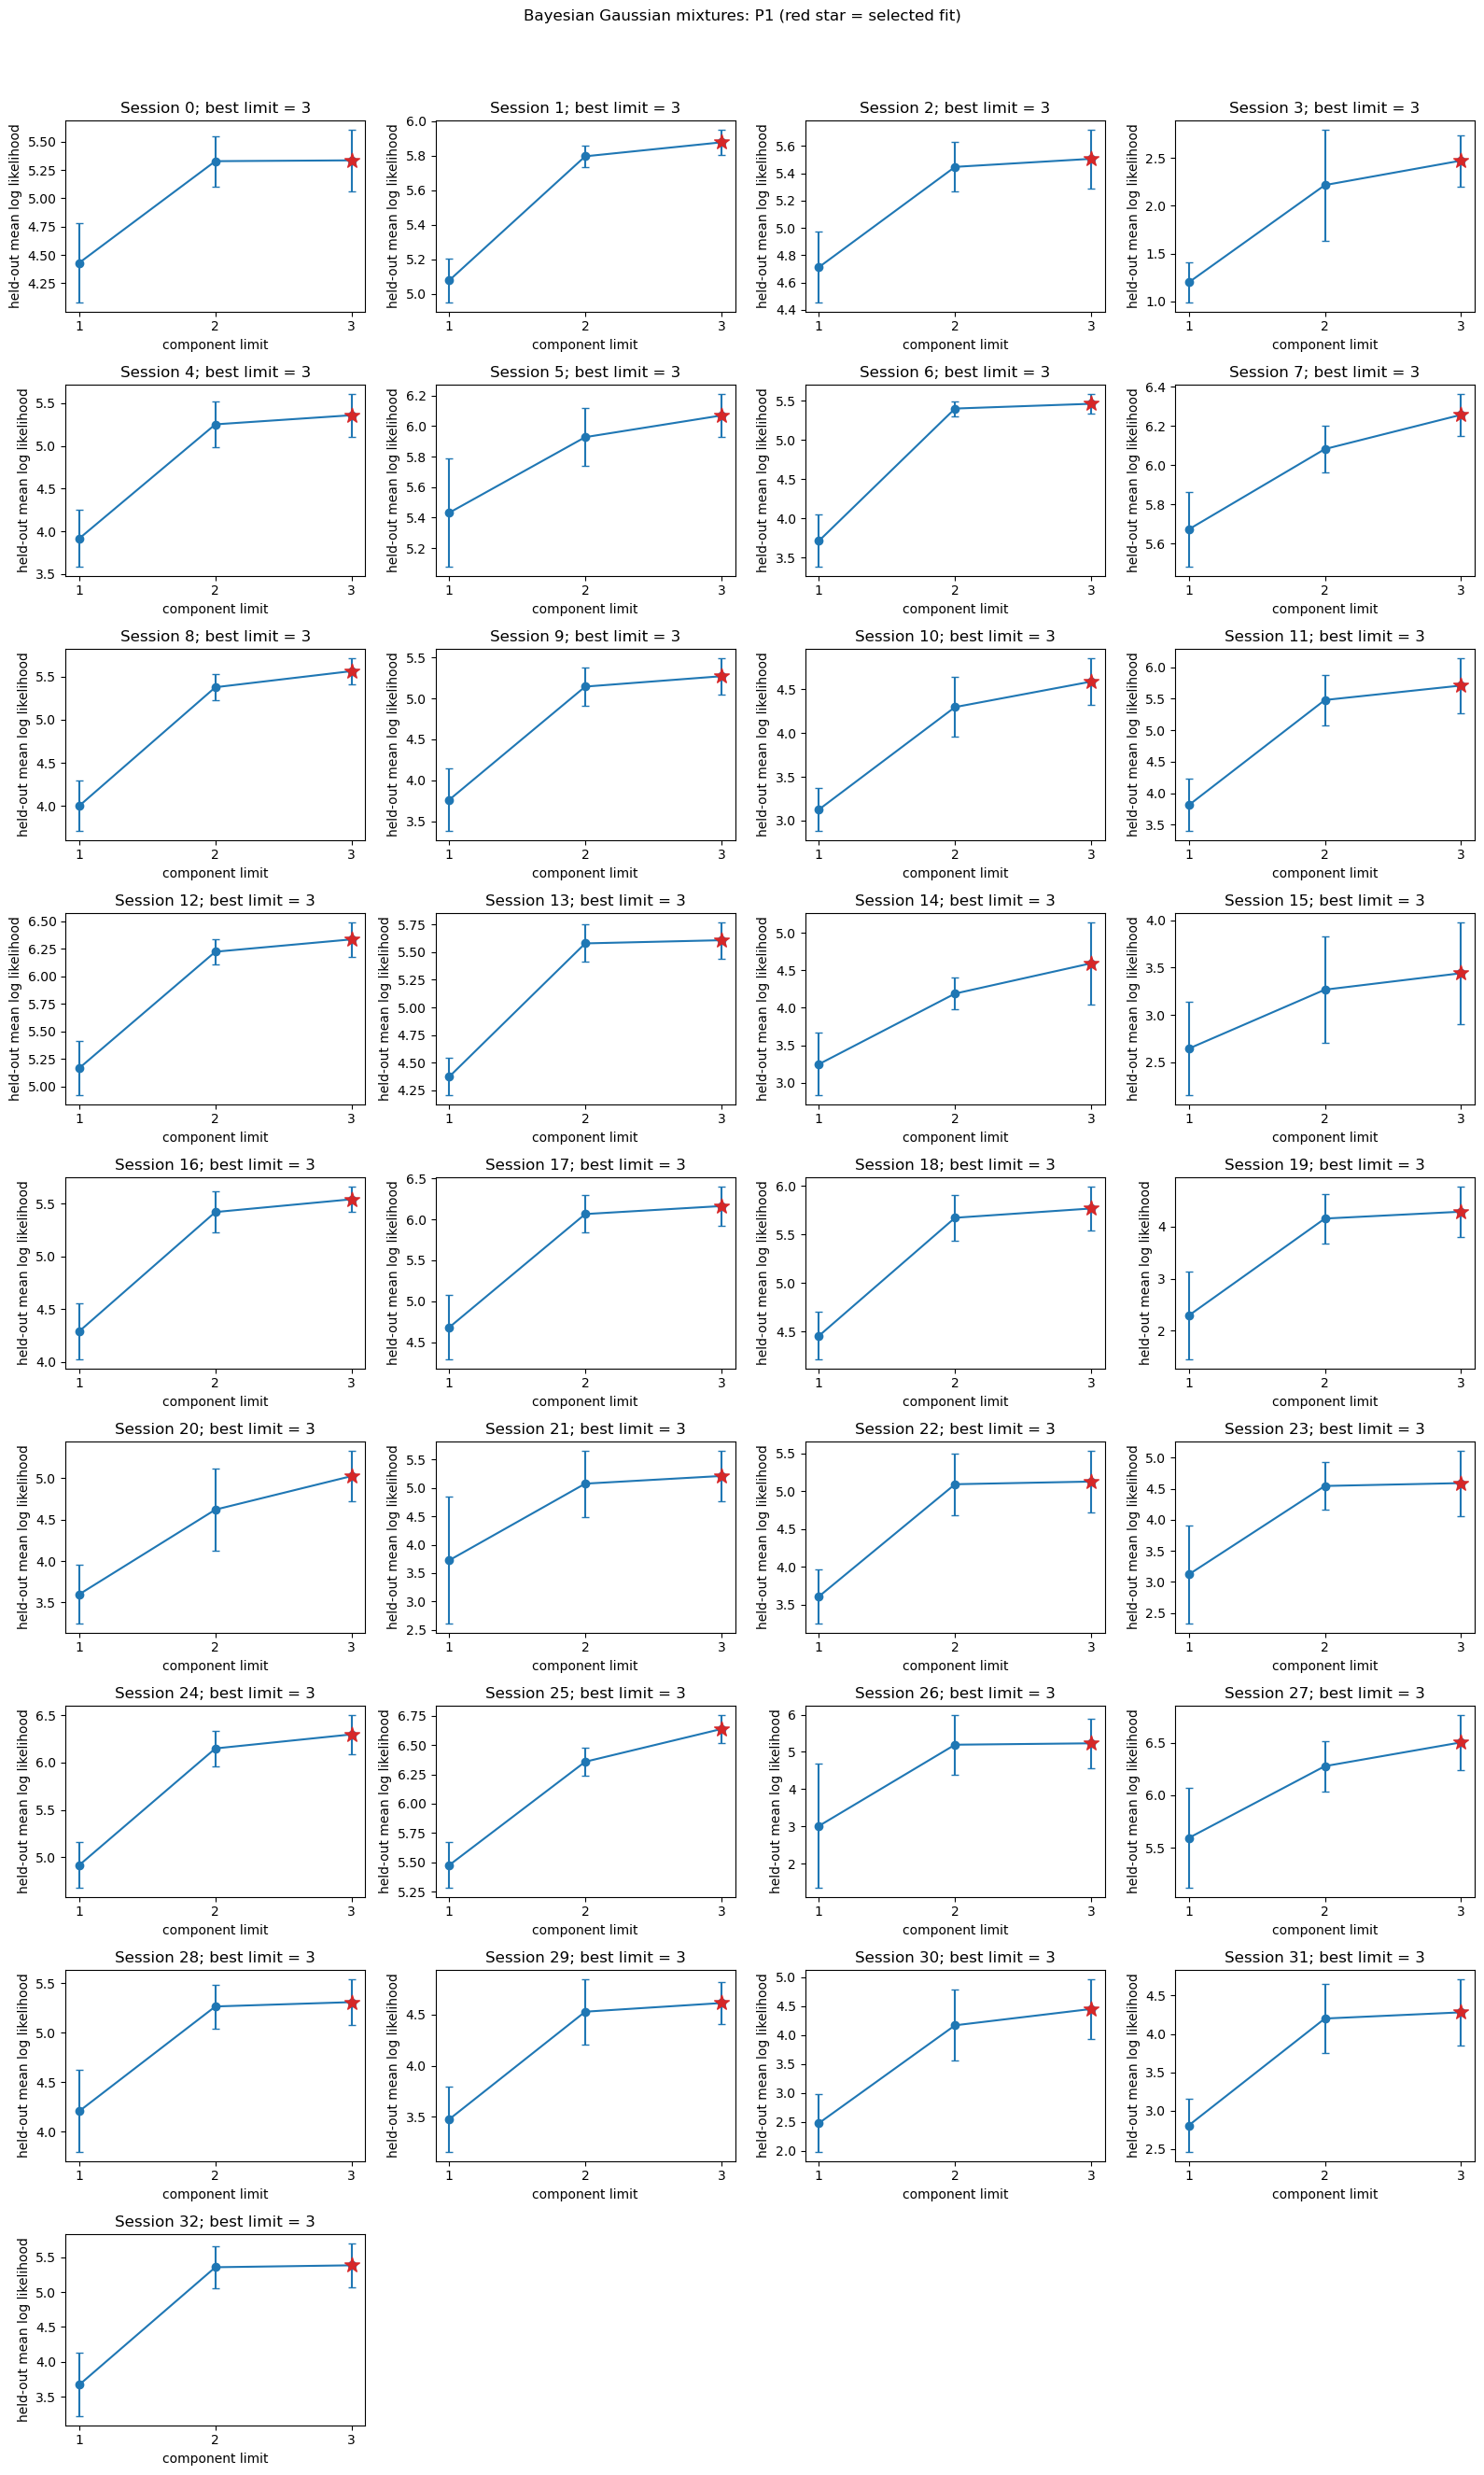

In [197]:
# Compare component counts within each session; higher CV log likelihood is better.
n_columns = 4
n_rows = int(np.ceil(len(bgmm_results) / n_columns))
fig, axes = plt.subplots(n_rows, n_columns, figsize=(4 * n_columns, 3 * n_rows), squeeze=False)
for ax, (bgmm_fx, result) in zip(axes.ravel(), bgmm_results.items()):
    scores = bgmm_summary[bgmm_summary['session'] == bgmm_fx].sort_values('n_components')
    valid = scores[np.isfinite(scores['cv_mean_log_likelihood'])]
    ax.errorbar(
        valid['n_components'], valid['cv_mean_log_likelihood'],
        yerr=valid['cv_std_log_likelihood'], fmt='o-', capsize=3,
    )
    selected = scores[scores['selected']]
    if not selected.empty:
        ax.scatter(selected['n_components'], selected['cv_mean_log_likelihood'],
                   marker='*', s=140, color='tab:red', zorder=3)
    ax.set_title(f'Session {bgmm_fx}; best limit = {result["best_n_components"]}')
    ax.set_xticks(bgmm_component_counts)
    ax.set_xlabel('component limit')
    ax.set_ylabel('held-out mean log likelihood')
for ax in axes.ravel()[len(bgmm_results):]:
    ax.set_visible(False)
fig.suptitle(f'Bayesian Gaussian mixtures: {bgmm_condition} (red star = selected fit)')
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


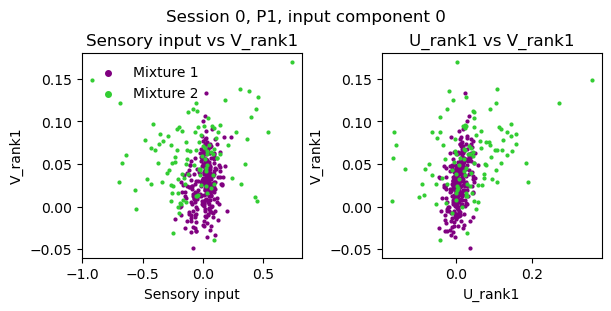

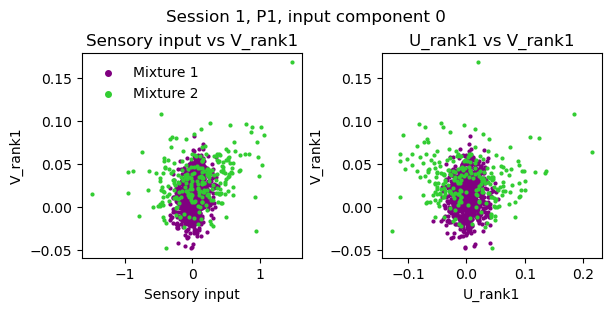

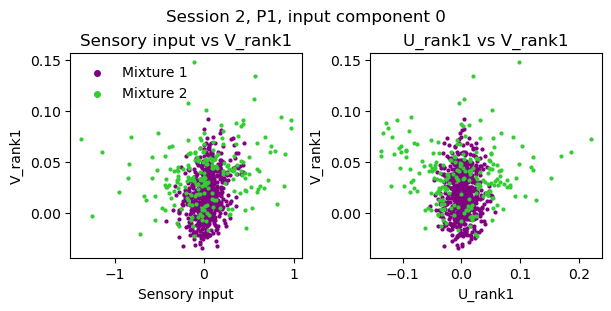

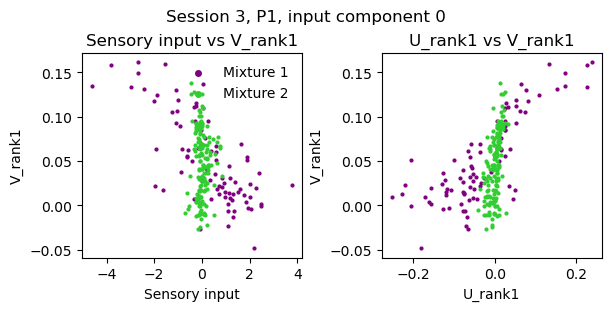

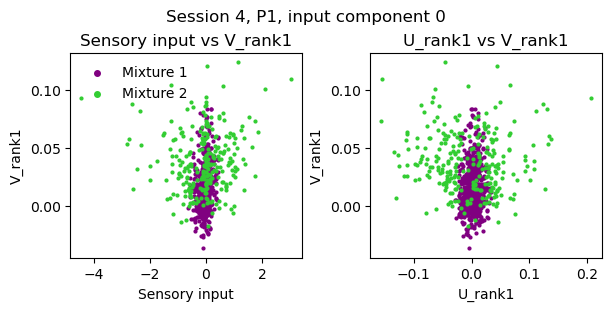

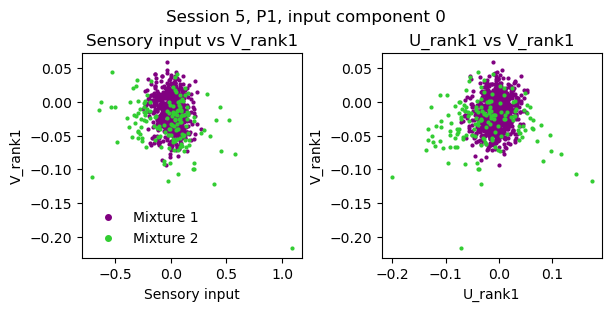

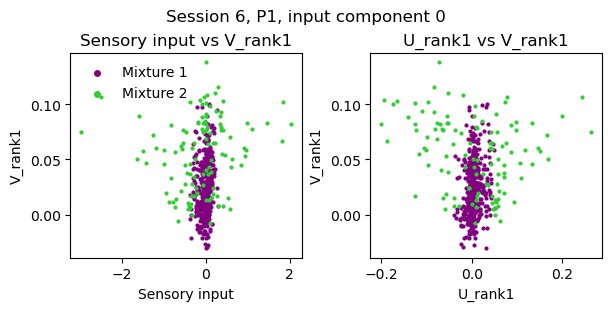

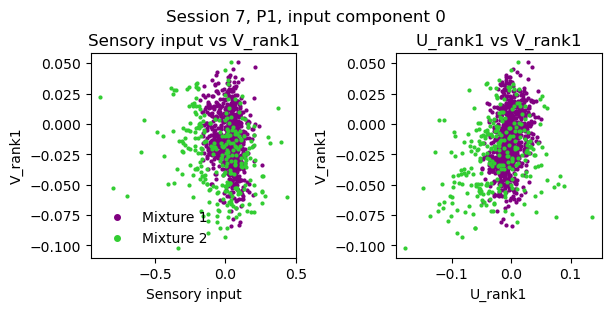

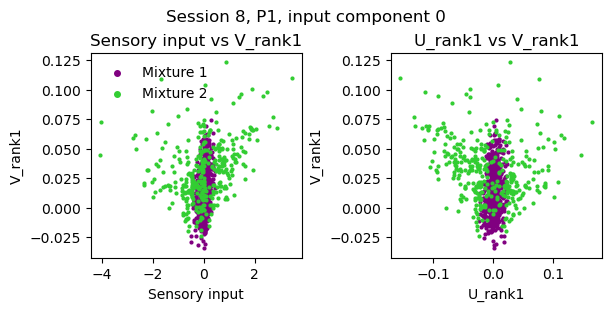

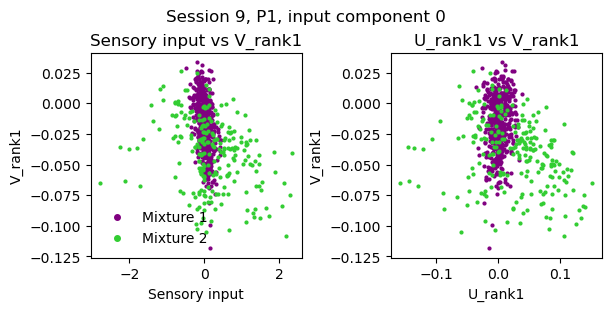

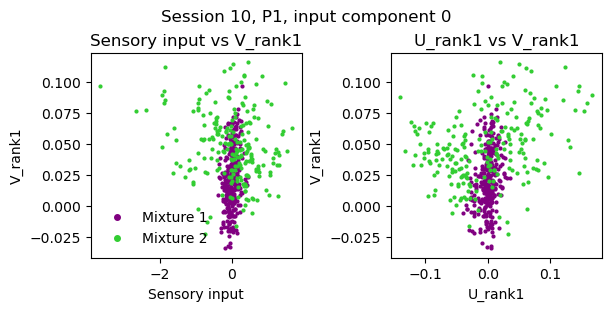

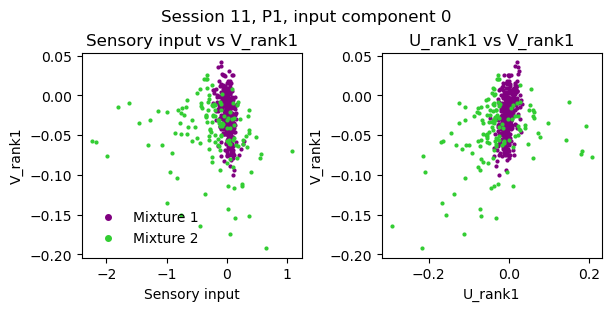

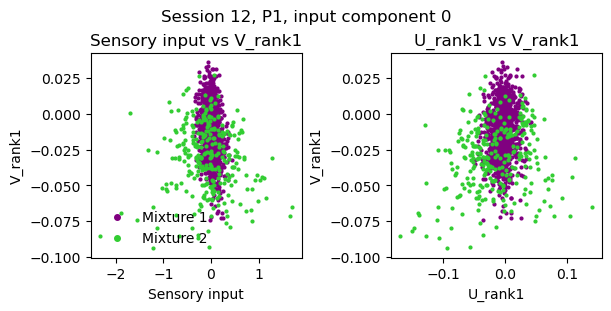

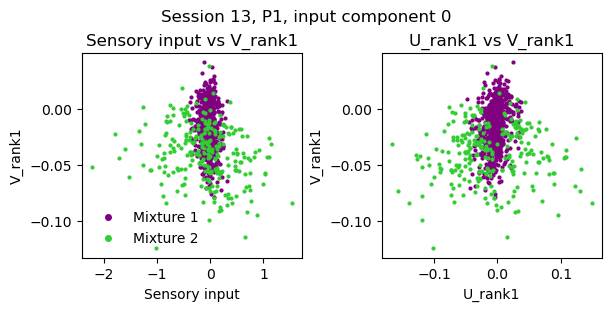

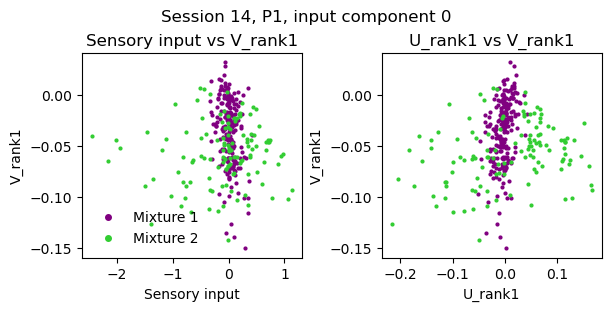

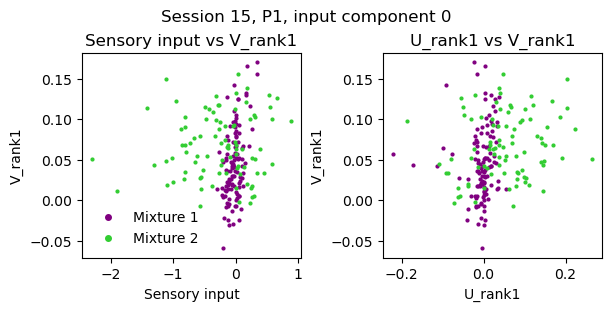

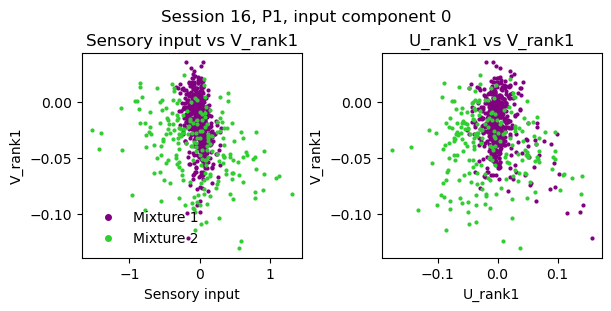

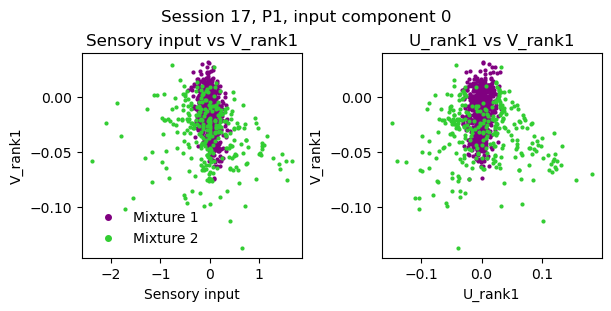

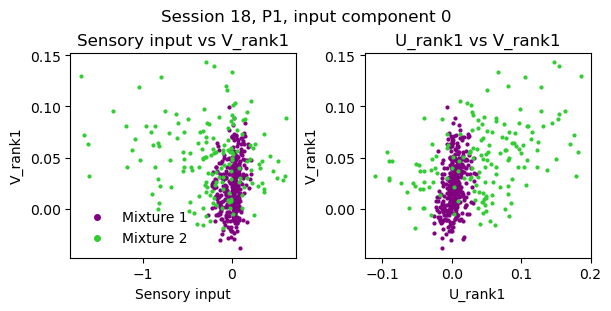

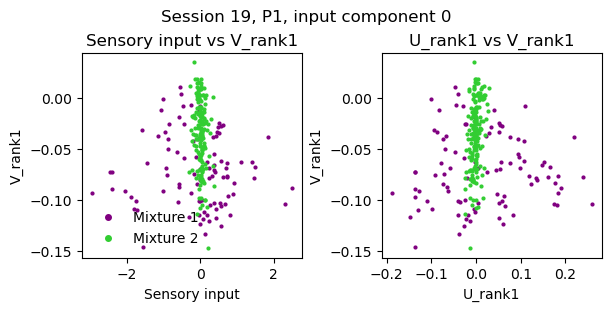

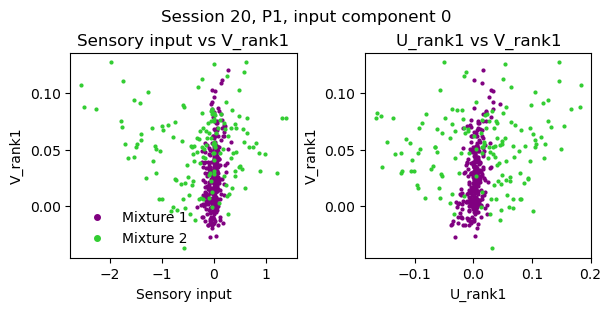

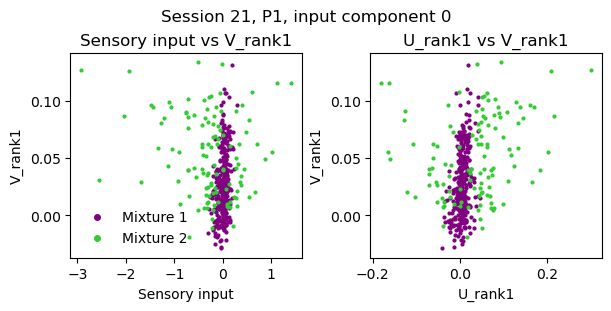

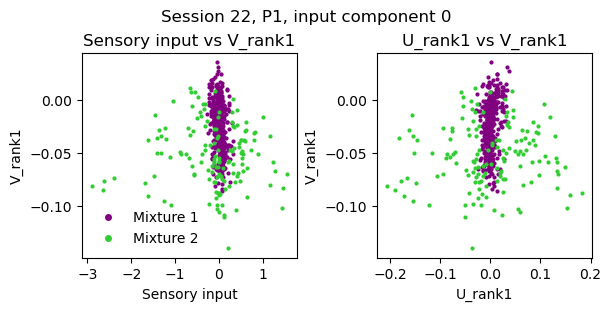

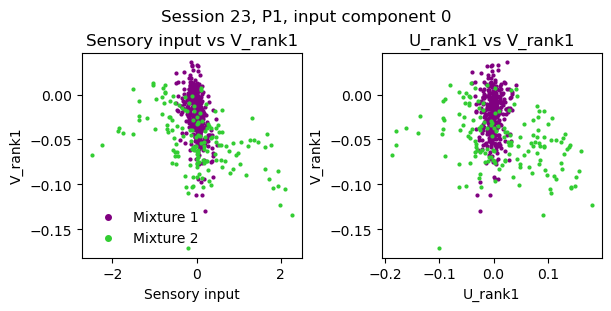

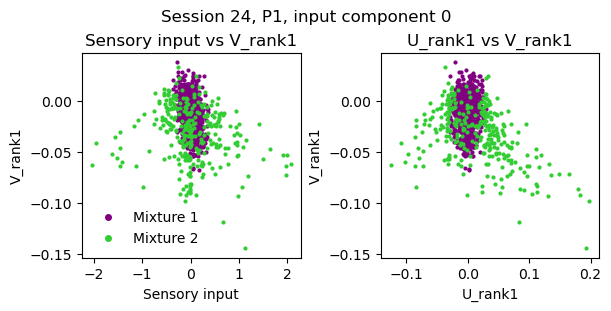

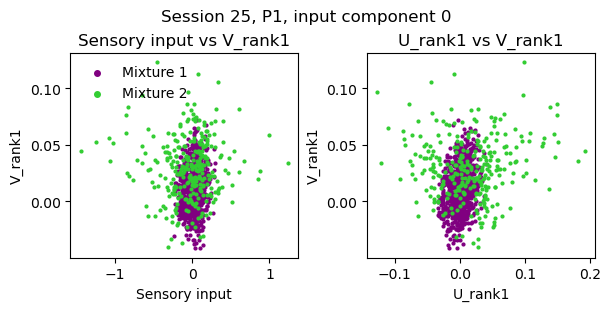

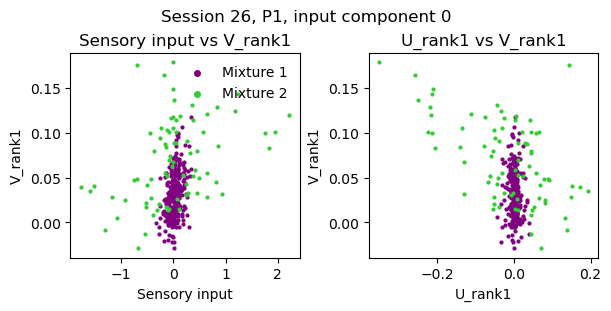

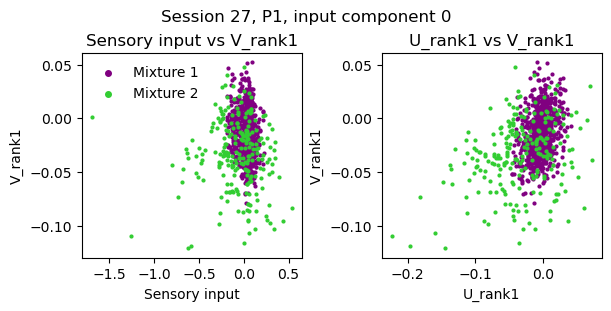

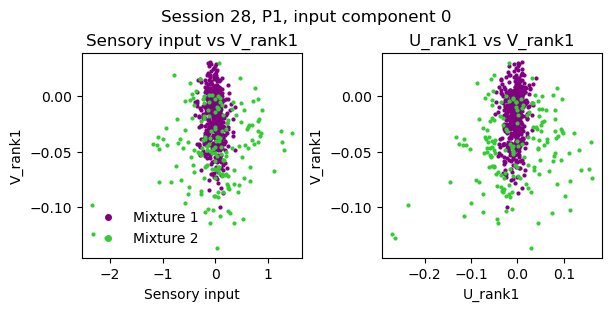

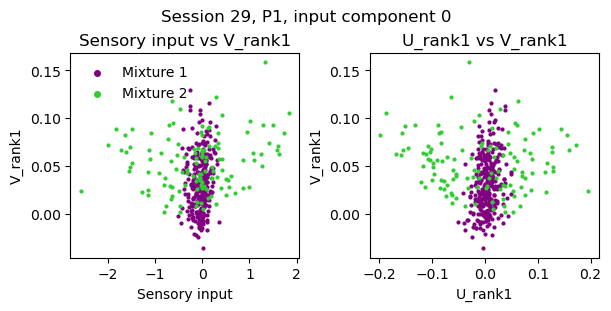

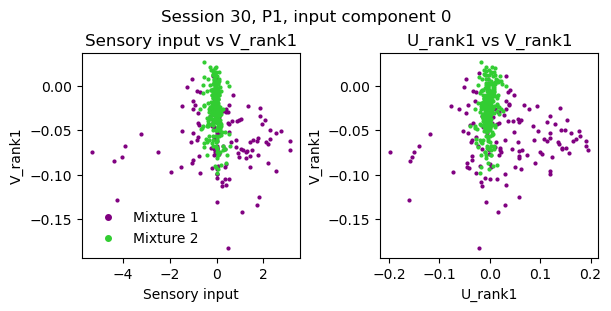

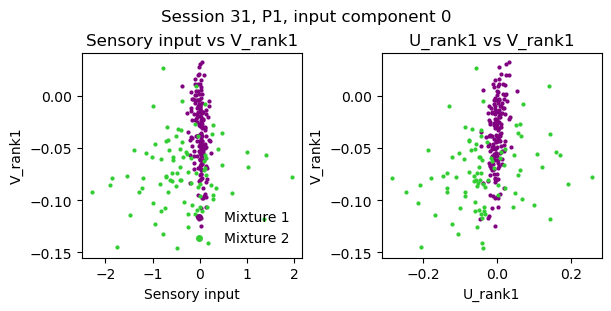

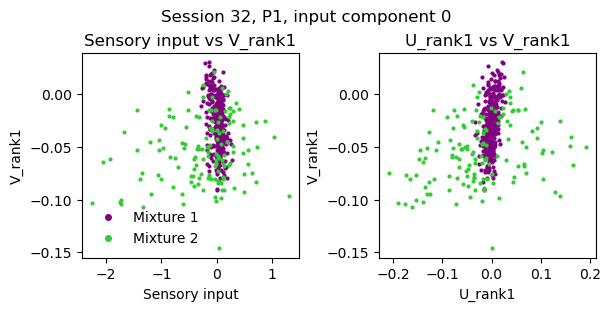

In [203]:
# Color original neurons using their assignments in the TWO-component fit.
# Features and labels share the same neuron order: columns are U, V, sensory, response.
mixture_colors = ('purple', 'limegreen')

for fx_scatter, fit in bgmm_results.items():
    if 2 not in fit['fits']:
        print(f'Session {fx_scatter}: no two-component fit; skipped.')
        continue
    features = fit['features']
    mixture_labels = fit['fits'][2]['labels']  # Model labels 0/1 mean mixtures 1/2.

    fig, axes = plt.subplots(1, 2, figsize=(6, 3), layout='constrained')
    for ax, x_column, x_label in zip(axes, (2, 0), ('Sensory input', 'U_rank1')):
        for mixture, color in enumerate(mixture_colors):
            members = mixture_labels == mixture
            ax.scatter(
                features[members, x_column], features[members, 1],
                s=4, color=color, label=f'Mixture {mixture + 1}',
            )
        ax.set(xlabel=x_label, ylabel='V_rank1', title=f'{x_label} vs V_rank1')
    axes[0].legend(frameon=False, markerscale=2)
    fig.suptitle(
        f'Session {fx_scatter}, {fit["condition"]}, '
        f'input component {fit["input_component"]}'
    )
    plt.show()
    plt.close(fig)


## Resample connectivity from the two-component mixture

For each session, jointly draw one `[U, V, sensory, response]` tuple per neuron from its two-component fit, then undo standardization. Reconstruct recurrent connectivity as `s * np.outer(U, V)`, retaining the original singular value `s` for the fitted mode. The sampled U/V entries are used directly as factors, without renormalization, to preserve the sampled joint distribution.

Compare each of the four vectors with a scatter plot: original entries on the x-axis and resampled entries on the y-axis, paired by row index. Dashed lines show y = x. Samples represent new synthetic neurons, so matching row indices do not imply the same biological neuron. The trained network stays unchanged; arrays are stored in `resampled_connectivity[fx]`. Seed 0 makes the sampling reproducible.


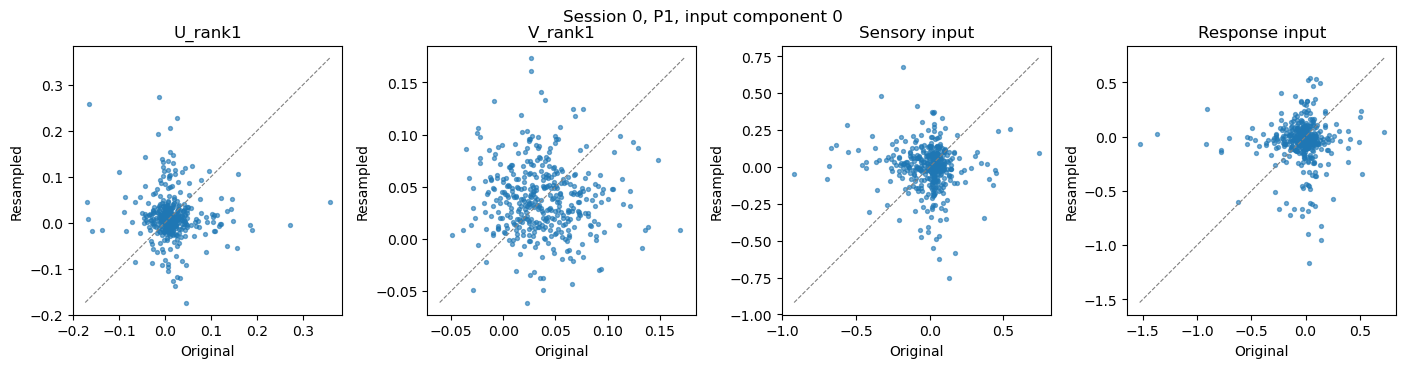

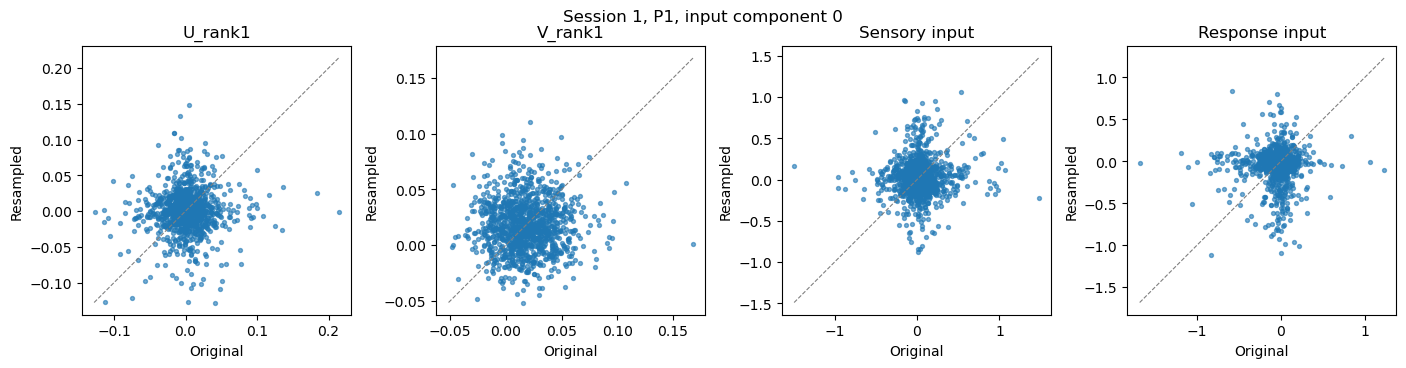

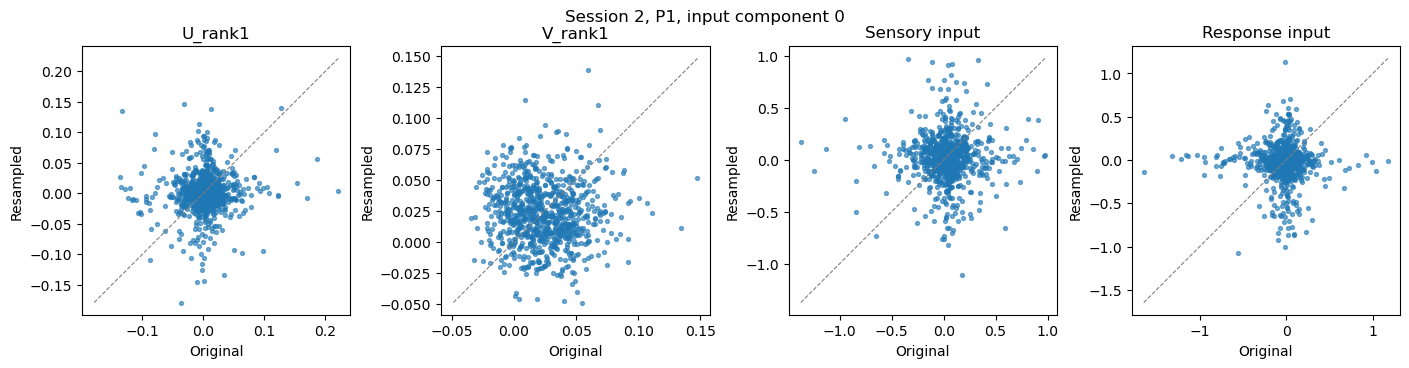

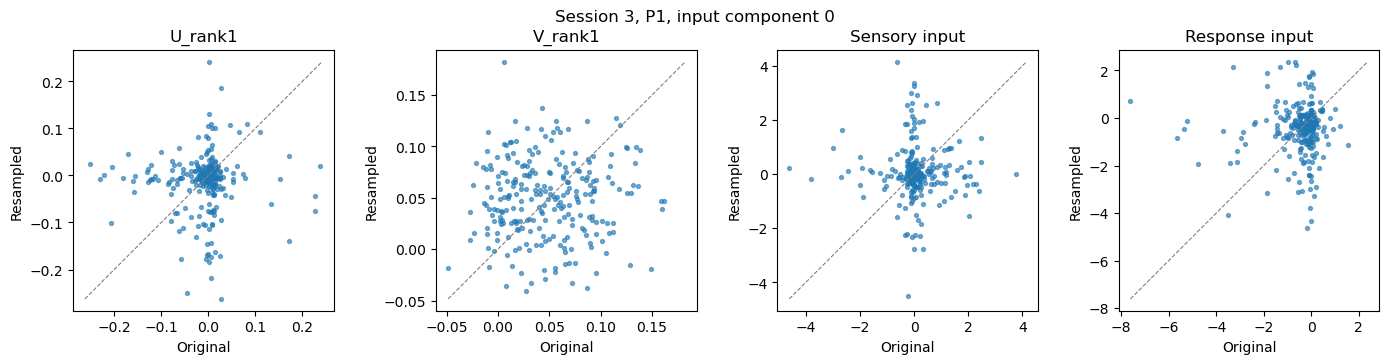

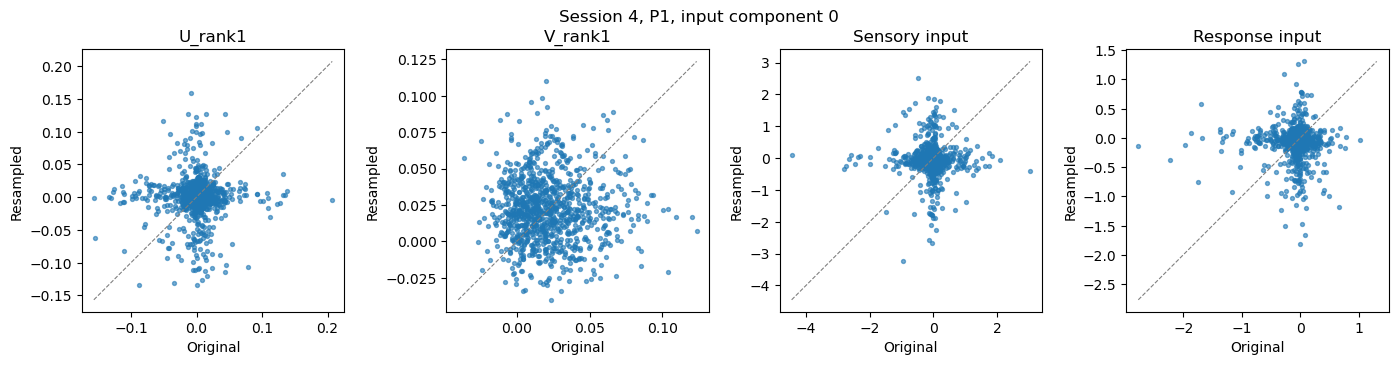

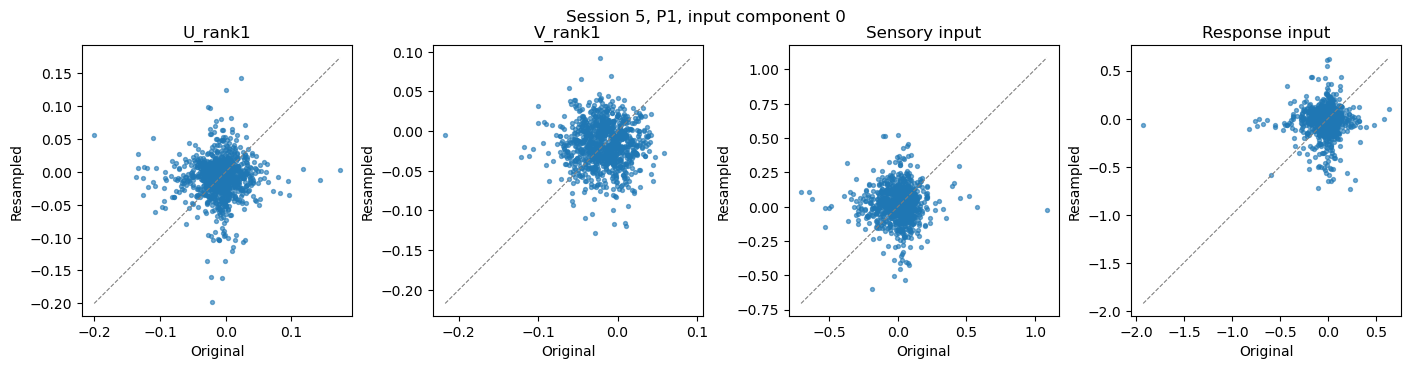

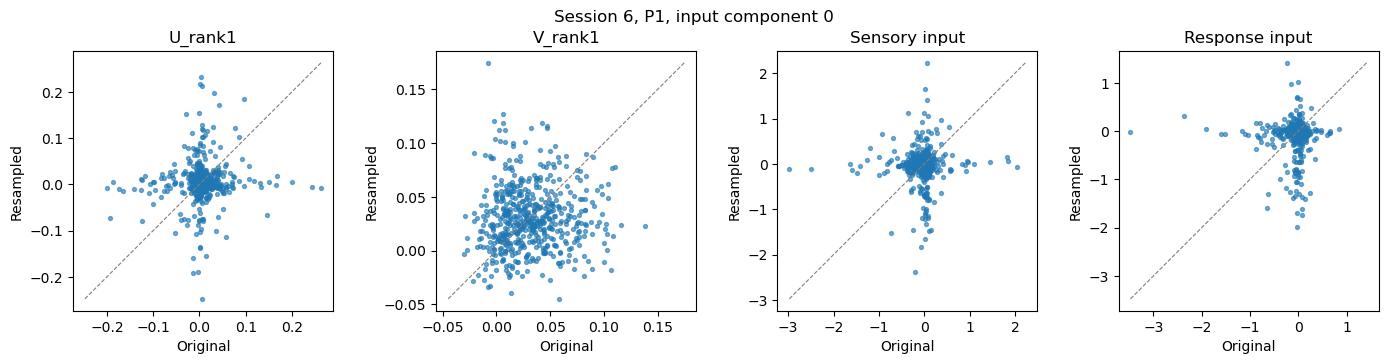

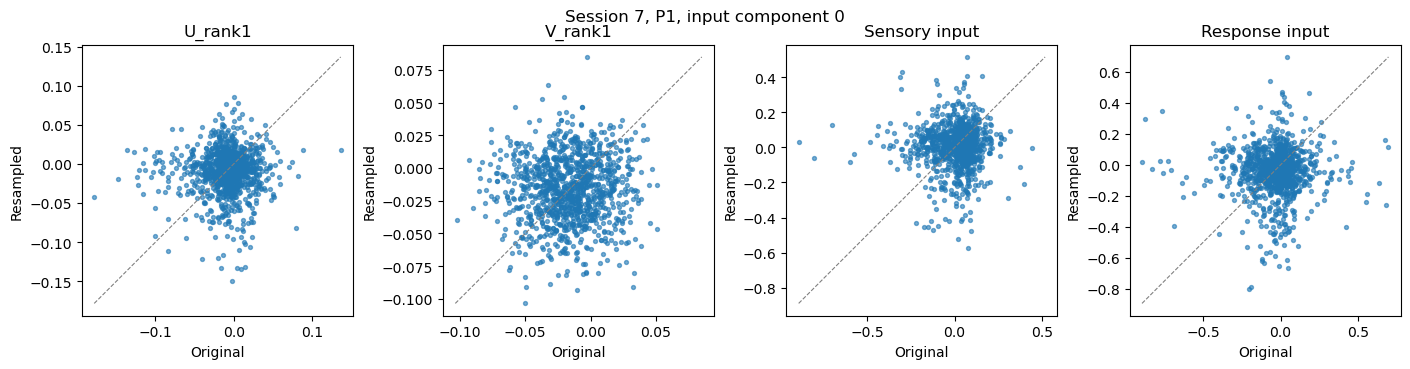

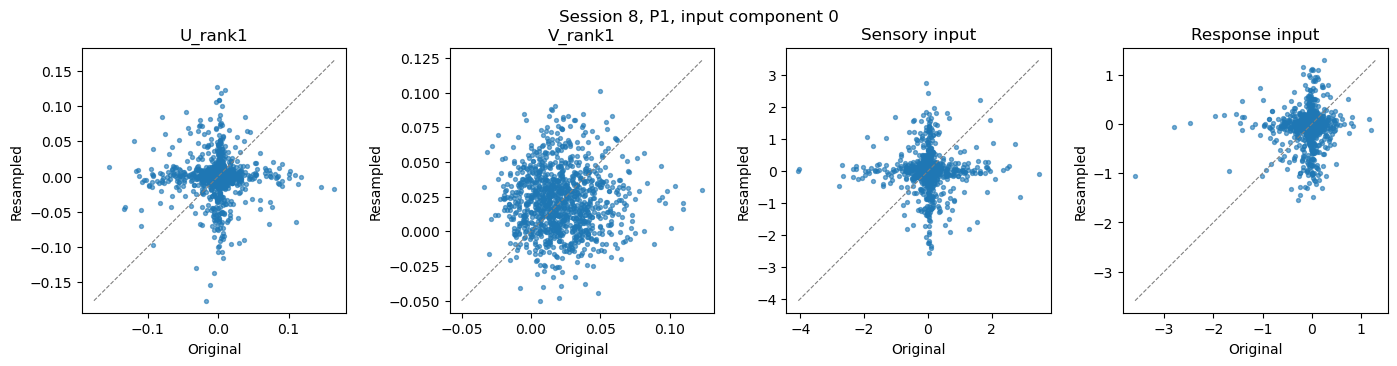

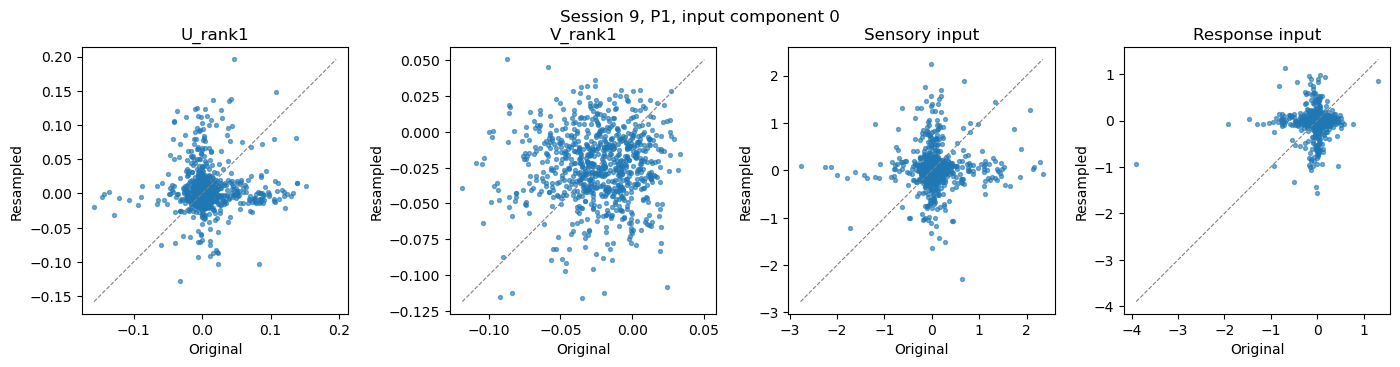

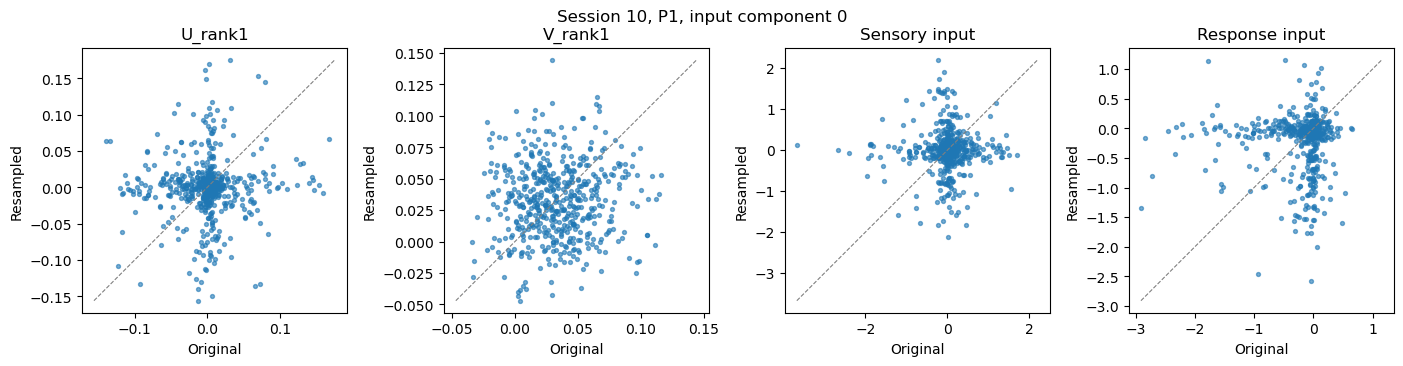

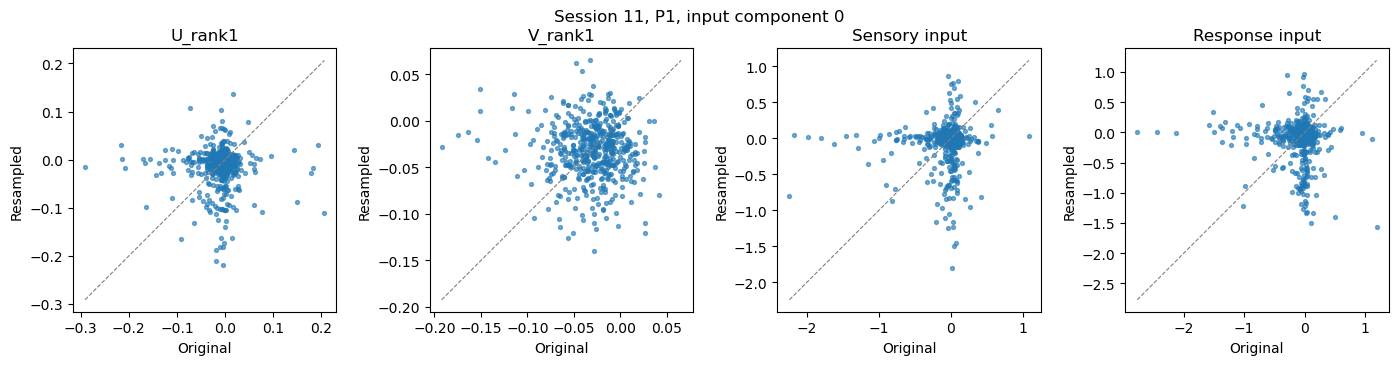

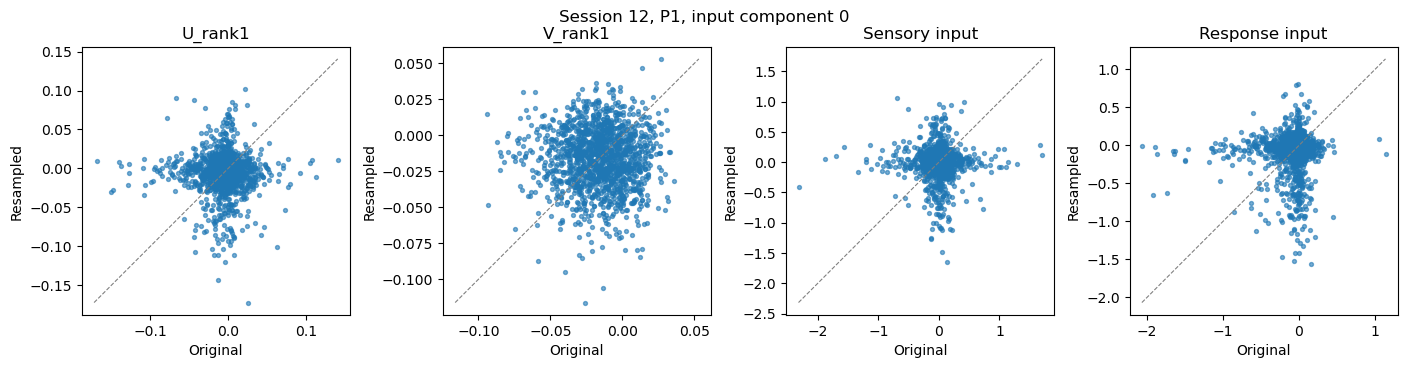

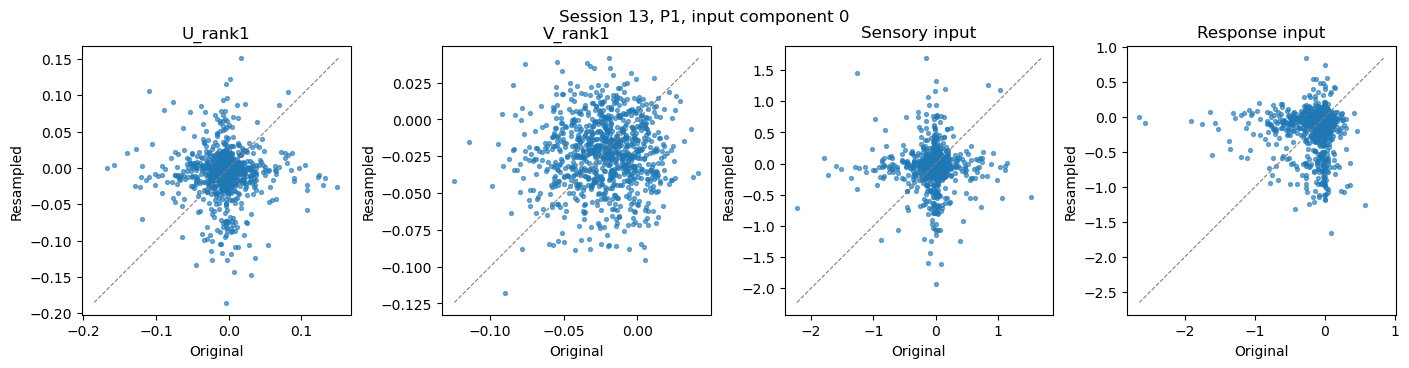

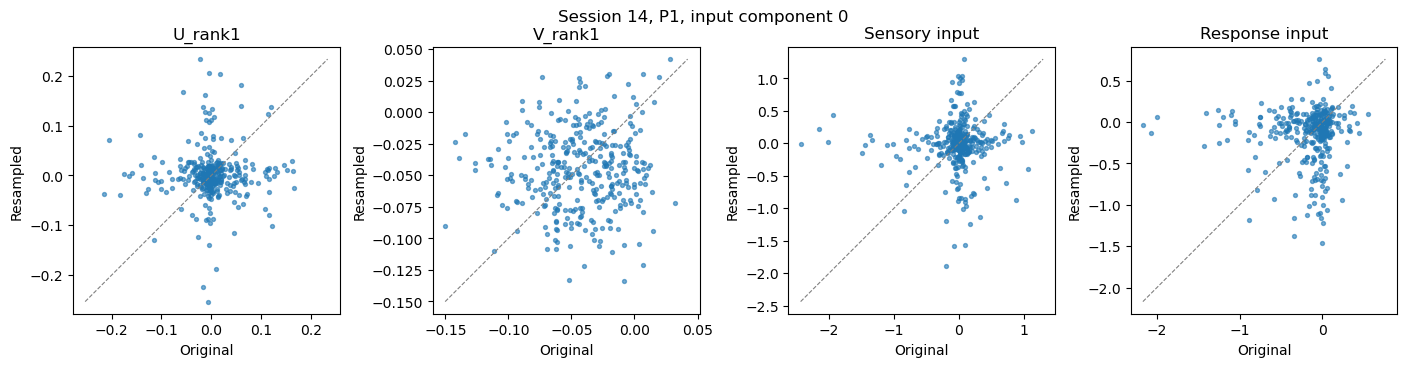

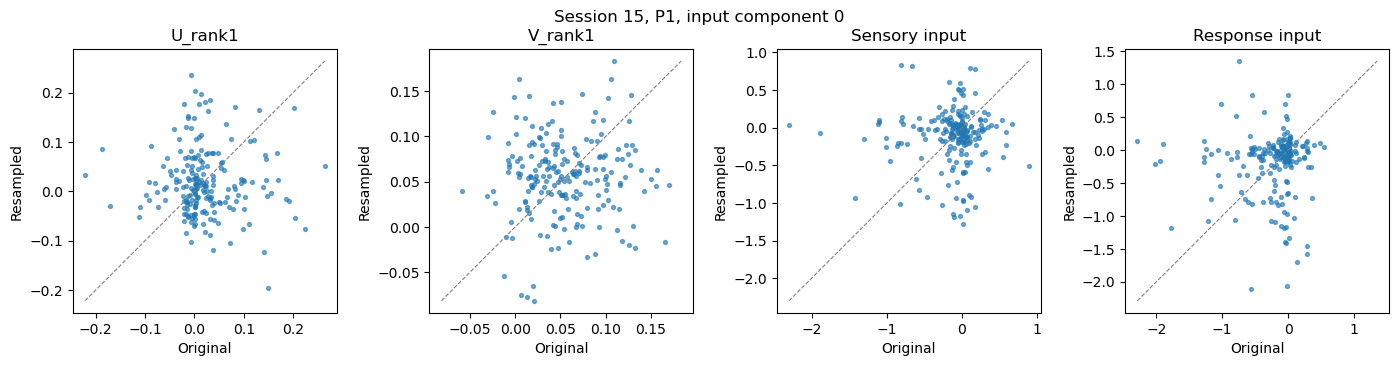

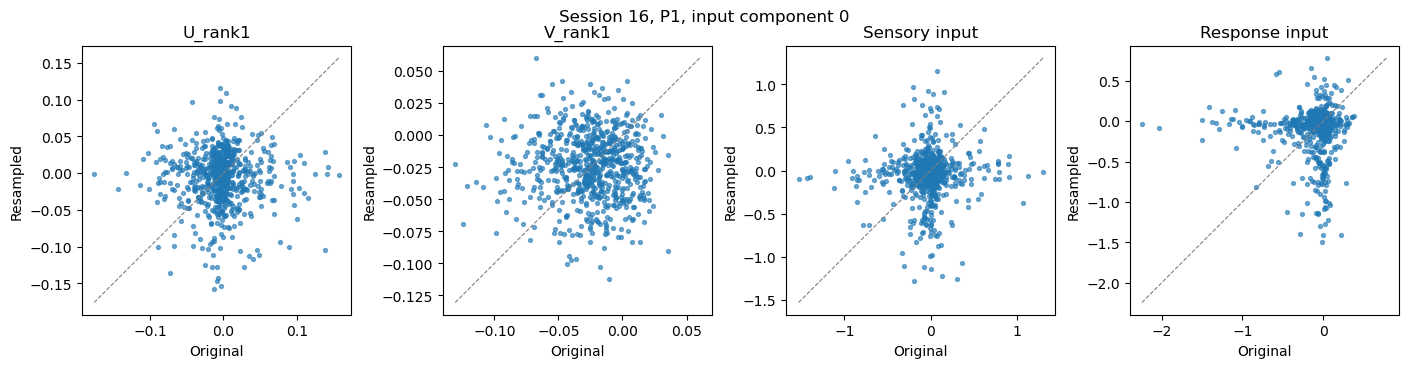

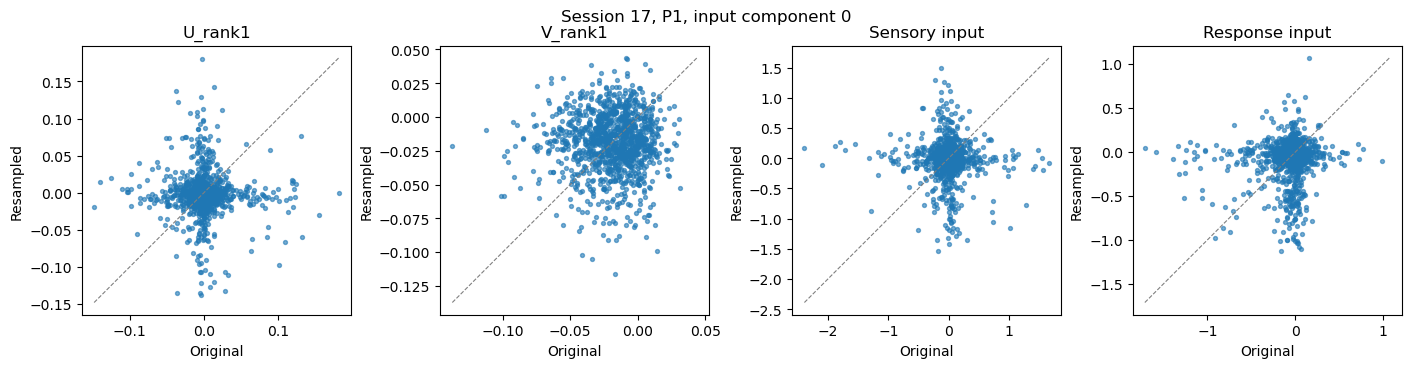

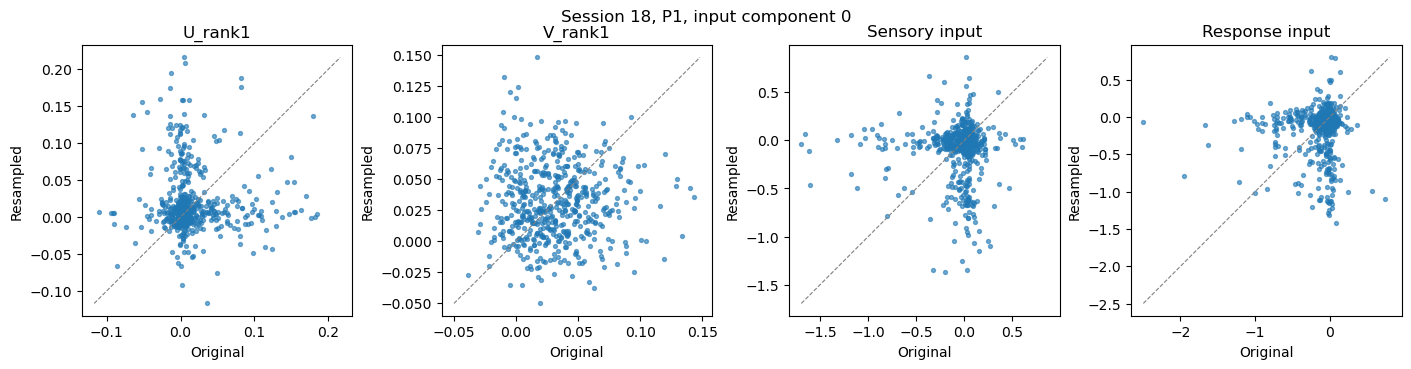

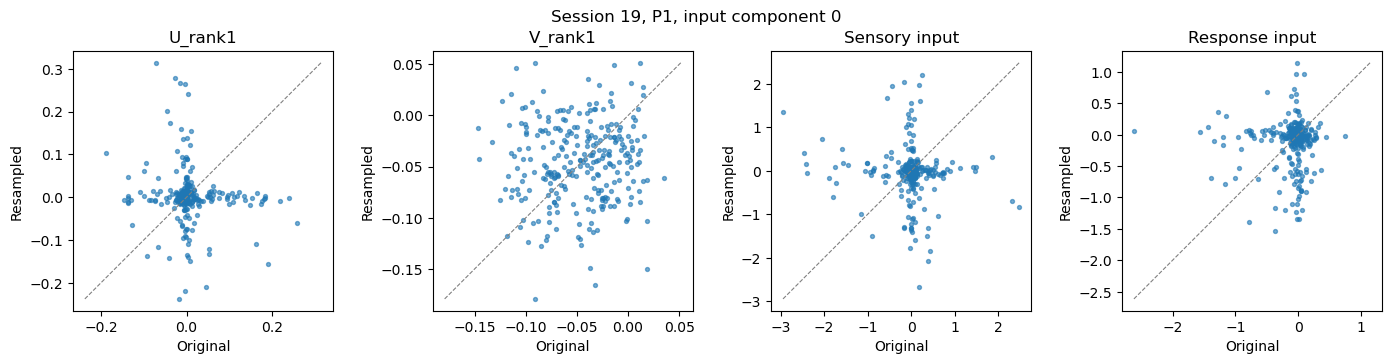

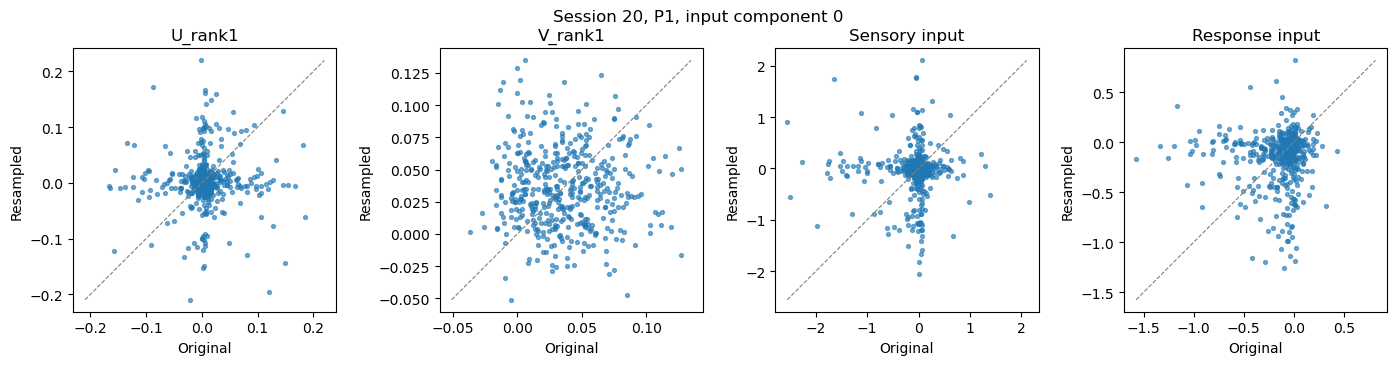

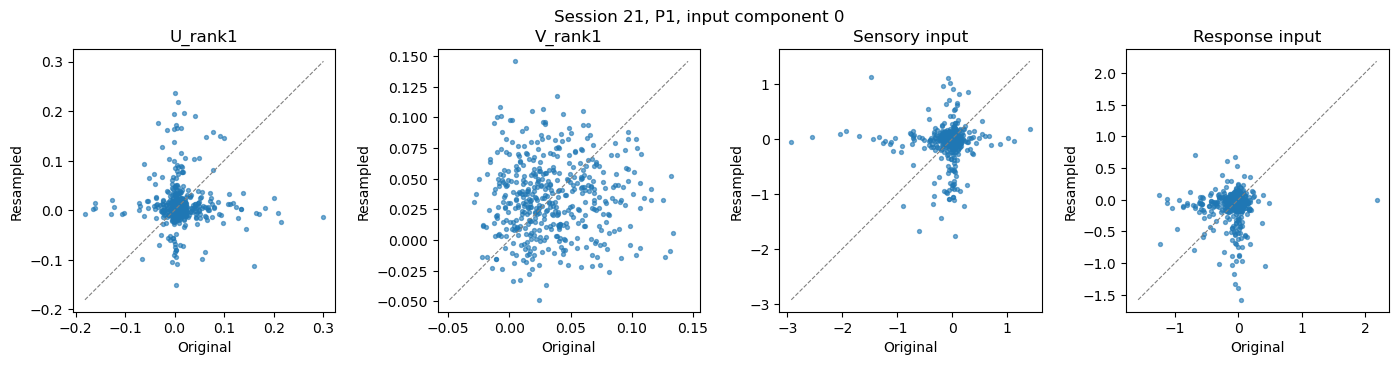

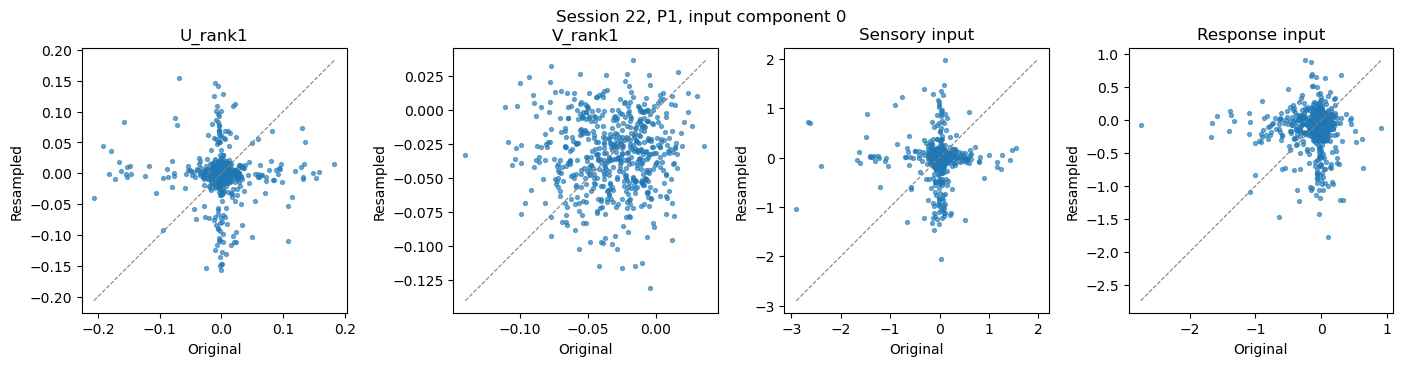

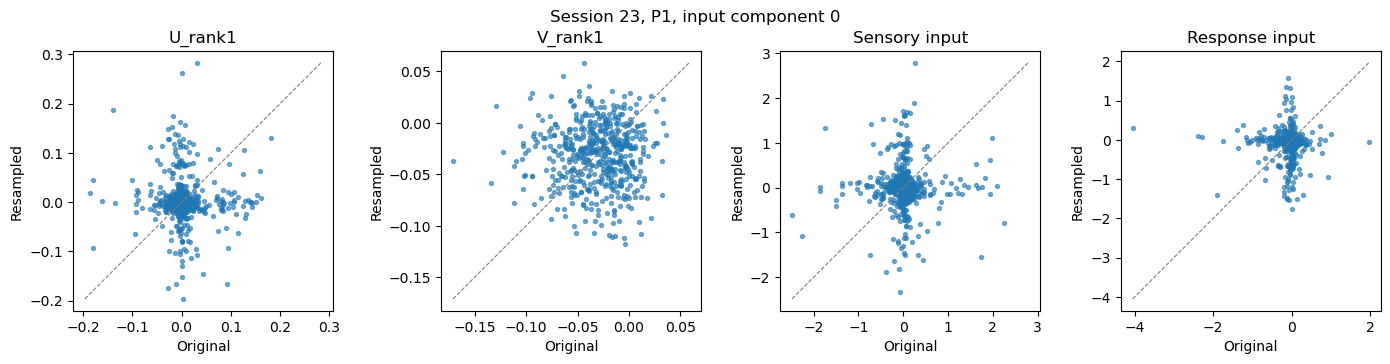

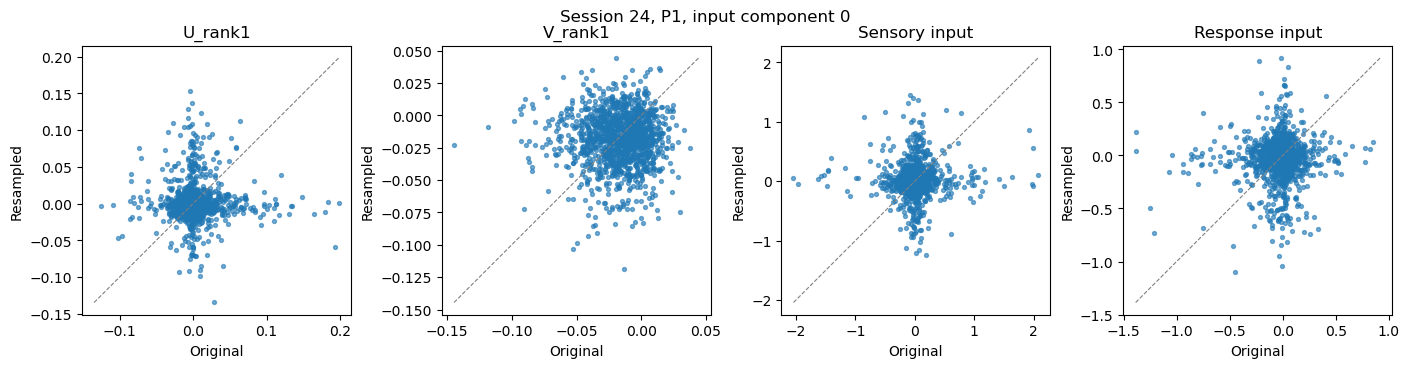

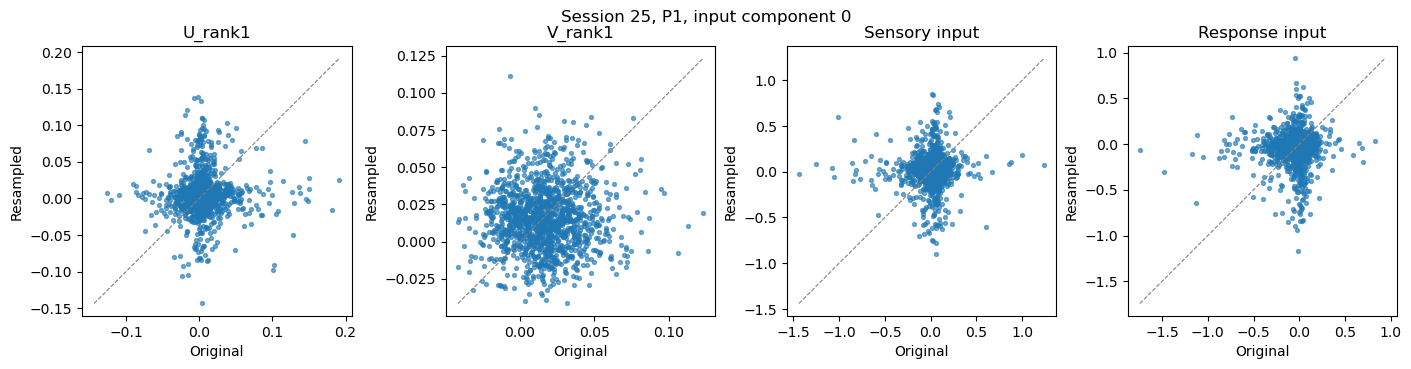

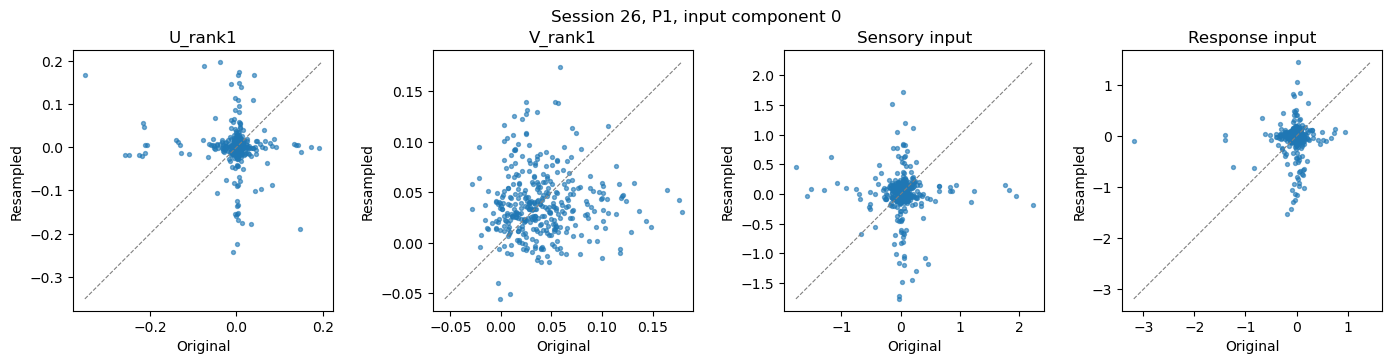

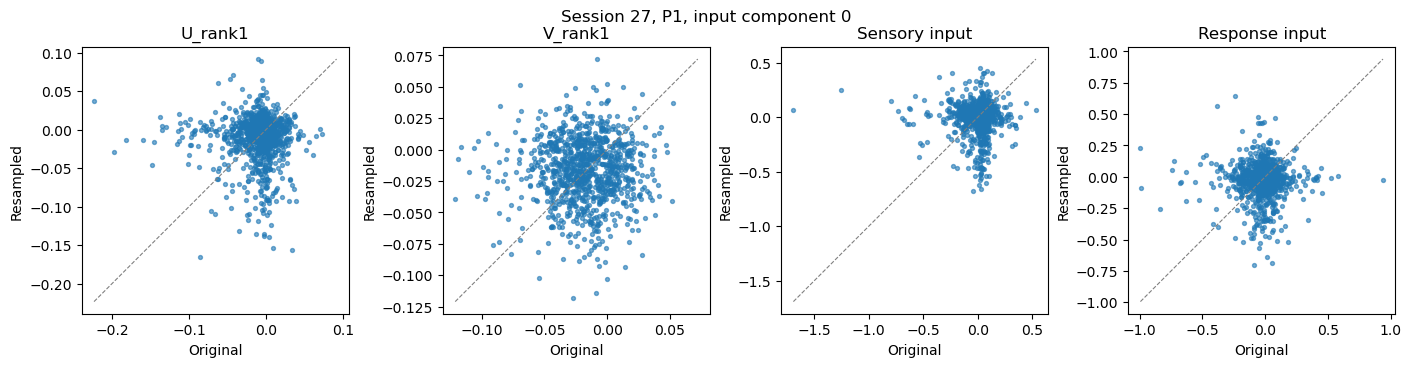

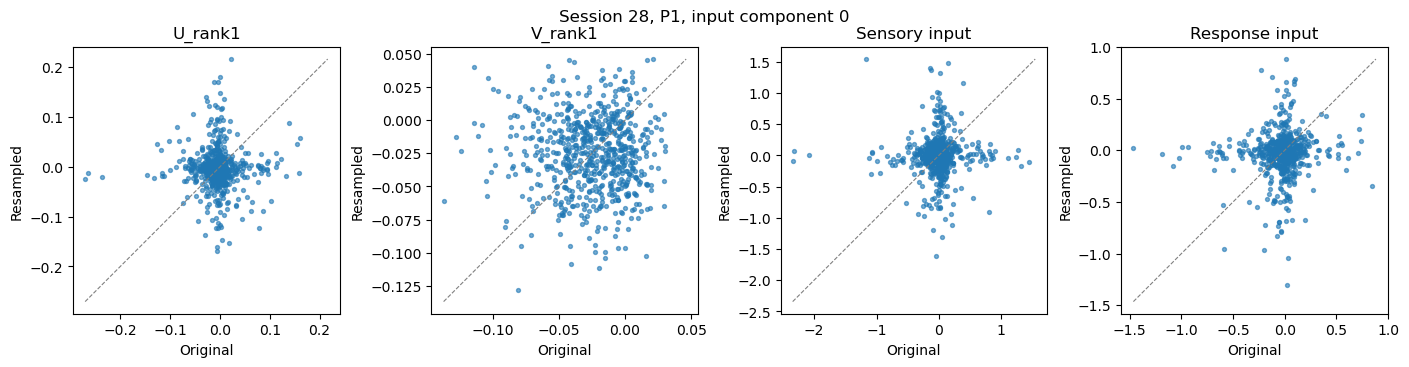

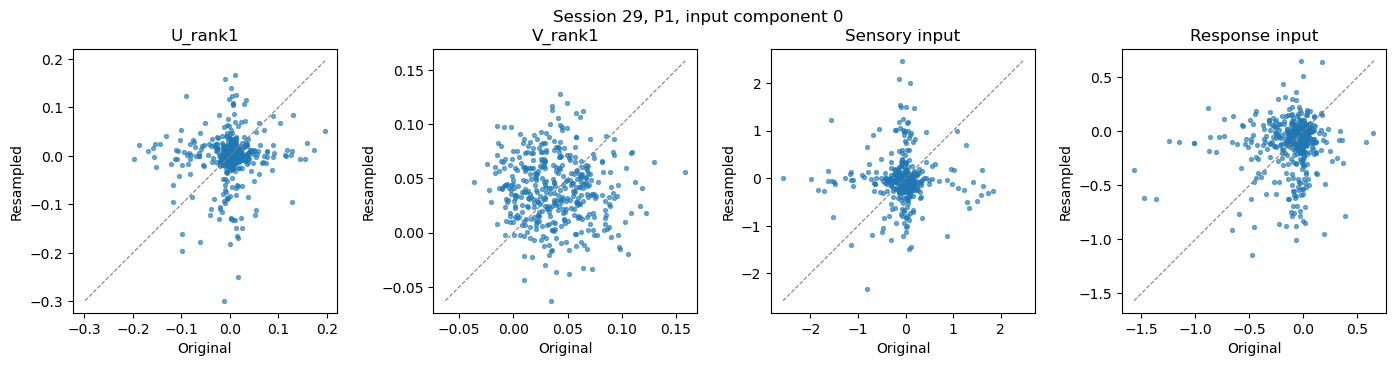

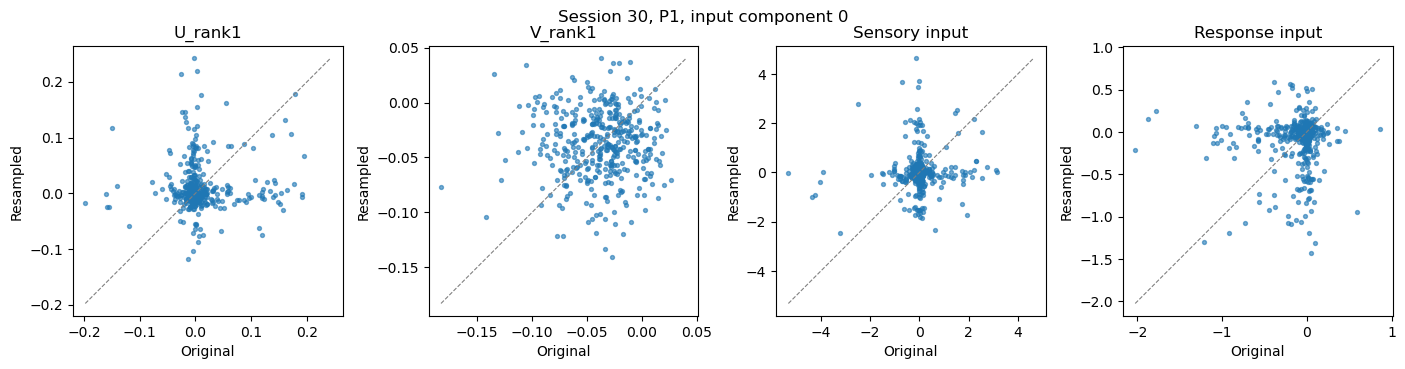

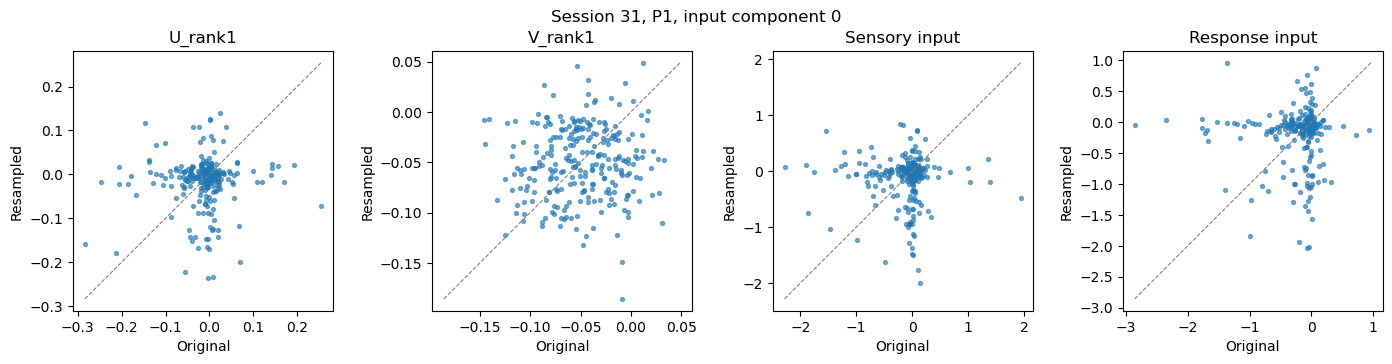

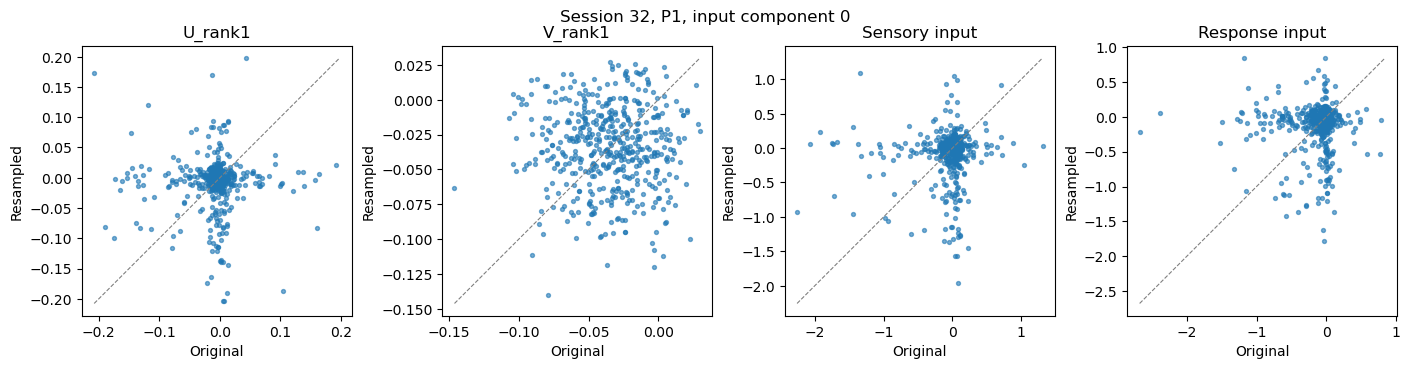

In [200]:
from copy import copy

resample_rng = np.random.RandomState(0)
resampled_connectivity = {}

for fx_resample, fit in bgmm_results.items():
    if 2 not in fit['fits']:
        print(f'Session {fx_resample}: no two-component fit; skipped.')
        continue
    X_original = fit['features']  # Columns: U, V, sensory, response.
    sampler = copy(fit['fits'][2]['model'])
    sampler.random_state = resample_rng
    X_sampled, sampled_labels = sampler.sample(len(X_original))
    X_sampled = fit['scaler'].inverse_transform(X_sampled)
    # Shuffle whole rows together: sample() groups rows by mixture component.
    order = resample_rng.permutation(len(X_sampled))
    X_sampled, sampled_labels = X_sampled[order], sampled_labels[order]
    u_sampled, v_sampled, sensory_sampled, response_sampled = X_sampled.T

    W_original = bgmm_rnn.recurrent_weight(fx_resample).detach().cpu().numpy()
    mode = fit['singular_mode']
    singular_value = np.linalg.svd(W_original, compute_uv=False)[mode]
    W_sampled = singular_value * np.outer(u_sampled, v_sampled)
    resampled_connectivity[fx_resample] = {
        'U': u_sampled, 'V': v_sampled,
        'sensory': sensory_sampled, 'response': response_sampled,
        'W': W_sampled, 'component_labels': sampled_labels,
        'singular_value': singular_value, 'singular_mode': mode,
        'condition': fit['condition'], 'input_component': fit['input_component'],
    }

    fig, axes = plt.subplots(1, 4, figsize=(14, 3.5), layout='constrained')
    titles = ('U_rank1', 'V_rank1', 'Sensory input', 'Response input')
    for column, (ax, title) in enumerate(zip(axes, titles)):
        x, y = X_original[:, column], X_sampled[:, column]
        ax.scatter(x, y, s=8, alpha=0.6)
        limits = [min(x.min(), y.min()), max(x.max(), y.max())]
        ax.plot(limits, limits, '--', color='gray', lw=0.8)
        ax.set(title=title, xlabel='Original', ylabel='Resampled')
        ax.set_aspect('equal', adjustable='box')
    fig.suptitle(f'Session {fx_resample}, {fit["condition"]}, input component {fit["input_component"]}')
    plt.show()
    plt.close(fig)


## Unit activity: original and resampled networks

For each session in `resampled_connectivity`, copy its trained `SessionRNN` and replace recurrence with `s * U_resampled @ V_resampled.T`. Replace the sensory and response vectors for the sampled condition and input component; any additional input components retain their trained values. The left panel uses the full original recurrence; the right panel uses the resampled rank-one recurrence.

Both simulations use the same freshly drawn input timecourses and the existing same initial state inferred from the observed target prefix (zero for legacy checkpoints), input masks, time step, and dynamics. The original model is preserved. All units are shown using one color scale per pair. Rows are ordered by the original units' peak times, and the same order is applied to both panels. Resampled rows represent synthetic units, rather than matched biological neurons.

Activities are stored as `(neurons, time)` arrays in `resampled_activity_comparison[fx]['original']` and `resampled_activity_comparison[fx]['resampled']`, in their original row order. `neuron_order` stores the display ordering.


In [ ]:
from copy import deepcopy

rank1_sessions = np.where(effdim == 2)[0]
resampled_activity_comparison = {}

for fx_sim, sampled in resampled_connectivity.items():
    
    if fx_sim in rank1_sessions:
            
        original_session = bgmm_rnn.session_model(fx_sim)
        sampled_session = deepcopy(original_session).eval()
        condition_sim = sampled['condition']
        condition_index = original_session.conditions.index(condition_sim)
        component_index = sampled['input_component']
        tensor_options = dict(
            device=original_session.input_vectors.device,
            dtype=original_session.input_vectors.dtype,
        )

        with torch.no_grad():
            u = torch.as_tensor(sampled['U'], **tensor_options)
            v = torch.as_tensor(sampled['V'], **tensor_options)
            # Use the resampled factors and the retained original singular value.
            if sampled_session.recurrent_type == 'fullconn':
                sampled_session.W.copy_(sampled['singular_value'] * torch.outer(u, v))
            elif sampled_session.recurrent_type == 'lowrank':
                # sampled_session.U.zero_()
                # sampled_session.V.zero_()
                sampled_session.U[:, 0].copy_(u)
                sampled_session.V[:, 0].copy_(
                    v * (sampled['singular_value'] / sampled_session.recurrent_scale)
                )
            sampled_session.input_vectors[0, condition_index, component_index].copy_(
                torch.as_tensor(sampled['sensory'], **tensor_options)
            )
            sampled_session.input_vectors[1, condition_index, component_index].copy_(
                torch.as_tensor(sampled['response'], **tensor_options)
            )

            shared_timecourses = original_session.sample_input_timecourses()
            shared_initial_activity = original_session.initial_activity_from_targets(
                dataset["activity"][fx_sim],
            )
            was_training = original_session.training
            original_session.eval()
            try:
                original_activity = original_session(
                    input_timecourses=shared_timecourses,
                    initial_activity=shared_initial_activity,
                )[condition_sim].T.cpu().numpy()
                sampled_activity = sampled_session(
                    input_timecourses=shared_timecourses,
                    initial_activity=shared_initial_activity,
                )[condition_sim].T.cpu().numpy()
            finally:
                original_session.train(was_training)

        neuron_order = np.argsort(np.argmax(original_activity, axis=1))
        resampled_activity_comparison[fx_sim] = {
            'condition': condition_sim,
            'input_component': component_index,
            'original': original_activity,
            'resampled': sampled_activity,
            'neuron_order': neuron_order,
        }

        vmax = max(original_activity.max(), sampled_activity.max()) or 1.0
        fig, axes = plt.subplots(1, 2, figsize=(9, 4), layout='constrained')
        for ax, activity, title in zip(
            axes, (original_activity, sampled_activity),
            ('Original network', 'Resampled network (rank one)'),
        ):
            im = ax.imshow(activity[neuron_order], aspect='auto', cmap='jet', vmin=0, vmax=0.1)
            ax.set(title=title, xlabel='time bin', ylabel='units (original peak-time order)')
        fig.colorbar(im, ax=list(axes), label='activity', shrink=0.85)
        fig.suptitle(f'Session {fx_sim}, {condition_sim}, input component {component_index}')
        plt.show()
        plt.close(fig)
